## CS328 Assignment 3: Exercise Recognition and Rep Counting

The objective of this assignment is to build a complete pipeline for exercise recognition from phone accelerometer data. Fitness trackers and gym apps do this every day: they find when you are exercising, recognize the exercise, and count your reps. In this assignment, you will be working with the accelerometer data the class collected with Sensor Logger in the Exercises Study. Each recording is one set of one of eight exercises: squats, jumping jacks, push-ups, sit-ups, ab crunches, lunges, bicep curls, and lat raises.

You will get hands-on experience in several key aspects of mobile health sensing:
1. **Segmentation**: finding the exercise set inside a recording, and ignoring the rest and the phone handling at the start and the end.
2. **Rep counting**: turning the set into a number of reps with peak detection, on the right signal.
3. **Classification**: windowing, feature extraction, and model training, and combining the window predictions into one label per recording.
4. **Error analysis**: finding out which step of the pipeline caused each error.

Unlike A2, where every second of a recording was the same activity, an exercise recording has a beginning, an end, and separate reps in between. Errors also compound: if the segmentation keeps the phone handling, the rep counter counts it as reps, and the classifier sees windows that are not the exercise.

#### Imports Block

Make sure all imports are in this block below.

In [1]:
# -- IMPORTS START --
import pandas as pd
import glob
import os
import numpy as np
import matplotlib.pyplot as plt

from baseline import run_baseline
from segmentation import adaptive_segment, protocol_segment
from segmentation_exploration import run_segmentation_exploration
from rep_counting import count_reps as improved_count_reps
from rep_counting_exploration import run_rep_counting_exploration
from features import add_my_features as selected_window_features
from feature_exploration import run_feature_exploration
from classification_exploration import run_classification_exploration
from recording_predictions import predict_recordings as vote_recordings
from recording_exploration import run_recording_exploration
import joblib
from IPython.display import Image, display

from sklearn import tree, metrics
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
from scipy.signal import butter, filtfilt, find_peaks
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from util import (viz_tree, load_manifest, split_recordings, load_recording, prepare_recording,
                  calc_magnitude, remove_noise, add_features, baseline_features, no_segment,
                  baseline_segment, cut_segment, baseline_count_reps, build_feature_frames,
                  select_recordings, evaluate_rep_counter, rep_metrics, plot_segment)
# -- IMPORTS END --

# enable zooming into graphs
%matplotlib inline
plt.rcParams['figure.figsize'] = [9, 6] # width, height in inches

No event loop hook running.


#### About the data (read this before you start)

- **`data/manifest.csv`** has one row per recording: `path` (e.g., `data/squats/001_2026-09-10_01-40-18.csv`, a number and the date and time of the recording), `exercise`, `reps` (the number of reps the student counted), and `placement` (Hand, Trouser, Jacket, Armband, Bag/backpack).
- Each CSV is the Sensor Logger `Accelerometer` sensor: **linear acceleration in m/s² with gravity removed** (as in A2). `load_recording` returns `time` in seconds from the start of the recording, and the `x`, `y`, `z` axes.
- Most phones log at ~100 Hz, but a few recordings are at 50-60 Hz. Use the `sample_rate` that `load_recording` returns instead of hard-coding it.
- The protocol was: stand still ~5 s → do the set → stand still ~5 s → Stop. **Not everyone did this.** Many recordings start and end with phone handling (putting the phone in a pocket, taking it out to tap Stop), which looks like a short burst of large motion.
- **Placement matters.** With the phone in a trouser pocket, upper-body exercises (bicep curls, lat raises) barely move the phone, and some recordings are almost flat.
- **Reps are self-reported.** Most are right, but some may be off by a rep or two.
- **Some classes are small**: lat raises has 19 recordings and ab crunches 28, while squats has 106.

**Hint (why the magnitude is not enough for counting):** in a squat, going down and coming up both accelerate the phone, so the magnitude often has two peaks per rep. One axis (or the direction that moves the most) has one cycle per rep.

#### Helper functions (provided in util.py, do not modify)

| Function | What it does |
|-|-|
| `load_manifest(root)` | Reads `data/manifest.csv` |
| `split_recordings(manifest, test_size, random_state)` | Splits **recordings** (not windows) into two parts, with the same mix of exercises in both |
| `prepare_recording(path)` | `load_recording` → `calc_magnitude` → `remove_noise`. Returns `data` (columns `time`, `x`, `y`, `z`, `accel_mag`, `filtered_accel_mag`) and `sample_rate` |
| `no_segment(data, sample_rate)` | The whole recording, as `(start_sec, end_sec)` |
| `baseline_segment(data, sample_rate)` | Baseline segmentation: active where the 1 s moving std of `filtered_accel_mag` is above 0.5 m/s². Returns `(start_sec, end_sec)` from the first to the last active sample |
| `cut_segment(data, start_sec, end_sec)` | Keeps only the samples inside the segment |
| `baseline_count_reps(data, sample_rate, exercise)` | Baseline rep counter (A1-style): peaks of `filtered_accel_mag` above its mean, at least 1 s apart |
| `baseline_features(window, sample_rate)` | The 7 A2 baseline features (`add_features`) |
| `build_feature_frames(manifest, window_sec, segment_fn, feature_fn)` | For every recording: `prepare_recording` → `segment_fn` → `cut_segment` → windows of `window_sec` with 50% overlap → `feature_fn`. One row per window, plus the `exercise` and `recording` columns |
| `select_recordings(frames, manifest)` | Keeps only the windows of the recordings in `manifest` |
| `evaluate_rep_counter(manifest, segment_fn, count_fn)` | Runs `segment_fn` and `count_fn` on every recording. One row per recording with `true_reps`, `pred_reps`, and `error` (= pred − true) |
| `rep_metrics(results, by=None)` | `MAE` (mean absolute error in reps), `within_2` (share of recordings within ±2 reps), `bias` (above 0 = counting too many). Use `by='exercise'` or `by='placement'` for a breakdown |
| `plot_segment(data, segments, title)` | Plots `filtered_accel_mag` with one shaded span per segmentation, e.g. `{'baseline': (start_sec, end_sec)}` |

#### Train / validation / test split (provided)

Everyone uses the same split. **Train** recordings (70%) are split again into **fit** and **validation** recordings. Use fit and validation to choose your segmentation, window length, features, hyperparameters, and rep-counting settings. Use the **test** recordings only for the final numbers in the tables. Never pick a setting because it looks better on test.

**Note:** the validation set is small (76 recordings). With a different `random_state` in the split, the same model can score several points higher or lower, so a difference of a few points between two settings may just be noise. Only trust clear differences.

In [2]:
manifest = load_manifest('./data')
train_manifest, test_manifest = split_recordings(manifest, test_size=0.3, random_state=42)
fit_manifest, val_manifest = split_recordings(train_manifest, test_size=0.25, random_state=42)

print('train:', len(train_manifest), '| test:', len(test_manifest),
      '| fit:', len(fit_manifest), '| validation:', len(val_manifest))
assert (len(train_manifest), len(fit_manifest), len(val_manifest), len(test_manifest)) == (301, 225, 76, 129)
assert set(fit_manifest['path']).isdisjoint(val_manifest['path'])
assert set(train_manifest['path']).isdisjoint(test_manifest['path'])
assert set(fit_manifest['path']) | set(val_manifest['path']) == set(train_manifest['path'])
manifest.groupby('exercise').size()

train: 301 | test: 129 | fit: 225 | validation: 76
Out[2]: 
exercise
Ab crunches       28
Bicep curls       50
Jumping jacks     87
Lat raises        19
Lunges            42
Push-ups          58
Sit-ups           40
Squats           106
dtype: int64


Lat raises | placement: Hand | reps: 19 | sample rate: 100 Hz


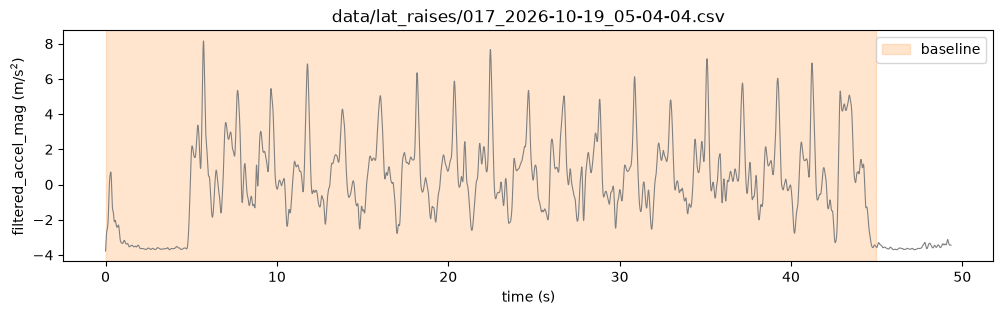

In [3]:
# Example: one recording with the baseline segmentation
row = fit_manifest.iloc[0]  # Inspect a fit recording; reserve test for final evaluation.
data, sample_rate = prepare_recording(row['path'])
print(row['exercise'], '| placement:', row['placement'], '| reps:', row['reps'], '| sample rate: %.0f Hz' % sample_rate)
plot_segment(data, {'baseline': baseline_segment(data, sample_rate)}, title=row['path'])

###  Assignment: Function 1: find_exercise_segment(data, sample_rate)

**Instructions:**
Define the `find_exercise_segment` function that finds the exercise set inside one recording. This is the **segmentation** axis in RUBRIC.md (exploration report §1).

- The function takes as arguments:
  - `data`: a DataFrame with the columns `time` (seconds), `x`, `y`, `z`, `accel_mag`, and `filtered_accel_mag` (from `prepare_recording`)
  - `sample_rate`: the sampling frequency of the recording
- The function returns `(start_sec, end_sec)`: the start and the end of the set, in seconds.

**Hints and Instructions:**
- As provided, the function returns the baseline segmentation, so you can run the whole notebook before writing it. Look at the plots: the baseline often keeps the phone handling at both ends, because a fixed threshold of 0.5 m/s² is easy to cross.
- Ideas to try:
  - **Protocol-based**: the protocol asks for ~5 s of standing still at both ends, so drop the first and the last few seconds. Simple, but it cuts reps when someone did not stand still.
  - **Adaptive threshold**: set the threshold from the recording itself, e.g., between its quiet level (a low percentile of the moving std) and its active level (a high percentile), instead of a fixed 0.5 m/s².
  - **Ignore short bursts**: phone handling lasts 1-2 s, while a set lasts much longer. Drop active parts shorter than a few seconds, or keep only the longest one.
  - **Use the rep band**: reps are slow (one every 1-4 s), while handling is short and sharp. Band-pass the signal to ~0.2-1.5 Hz before measuring the energy.
- Compare the baseline with **at least one approach of your own** (exploration report §1). Write each approach as its own function with the same two arguments, so you can pass it to `evaluate_rep_counter` and `build_feature_frames`. Keep the best one as `find_exercise_segment`. You will measure the effect of segmentation in the rep counting and classification sections.

In [4]:
def find_exercise_segment(data, sample_rate):
    # Adaptive threshold, short-gap joining, longest motion bout, and padding.
    # Method and settings live in segmentation.py.
    return adaptive_segment(data, sample_rate)


## Assignment-Segmentation: Visual Check

1. **Plot** at least **6 recordings** from `fit_manifest` with different exercises and placements, with the baseline and your segmentation, e.g. `plot_segment(data, {'baseline': ..., 'yours': ...})`.

2. **Find** one recording where the baseline fails and one where your method fails. Use them in §1 of your exploration report.

3. **Interpretation of the results**: What does the baseline get wrong? What does your method fix, and where does it still break?

Evaluating baseline: counting on training recordings...
Evaluating baseline: features and fixed classifiers...
Evaluating protocol_trim: counting on training recordings...
Evaluating protocol_trim: features and fixed classifiers...
Evaluating adaptive: counting on training recordings...
Evaluating adaptive: features and fixed classifiers...
     approach      split  recordings      MAE  within_2     bias
     baseline      train         301 7.980066  0.196013 4.611296
     baseline        fit         225 7.977778  0.213333 4.804444
     baseline validation          76 7.986842  0.144737 4.039474
protocol_trim      train         301 6.418605  0.299003 2.365449
protocol_trim        fit         225 6.555556  0.328889 2.600000
protocol_trim validation          76 6.013158  0.210526 1.671053
     adaptive      train         301 6.255814  0.262458 1.285714
     adaptive        fit         225 6.360000  0.280000 1.248889
     adaptive validation          76 5.947368  0.210526 1.394737
     ap

,approach,split,recordings,MAE,within_2,bias
2,baseline,validation,76,7.9868,0.1447,4.0395
5,protocol_trim,validation,76,6.0132,0.2105,1.6711
8,adaptive,validation,76,5.9474,0.2105,1.3947


,approach,model,fit_windows,validation_windows,validation_window_accuracy
0,baseline,Decision Tree,3677,1156,0.4187
1,baseline,Random Forest,3677,1156,0.4680
2,protocol_trim,Decision Tree,2889,882,0.4490
3,protocol_trim,Random Forest,2889,882,0.4955
4,adaptive,Decision Tree,2670,887,0.4994
5,adaptive,Random Forest,2670,887,0.4893


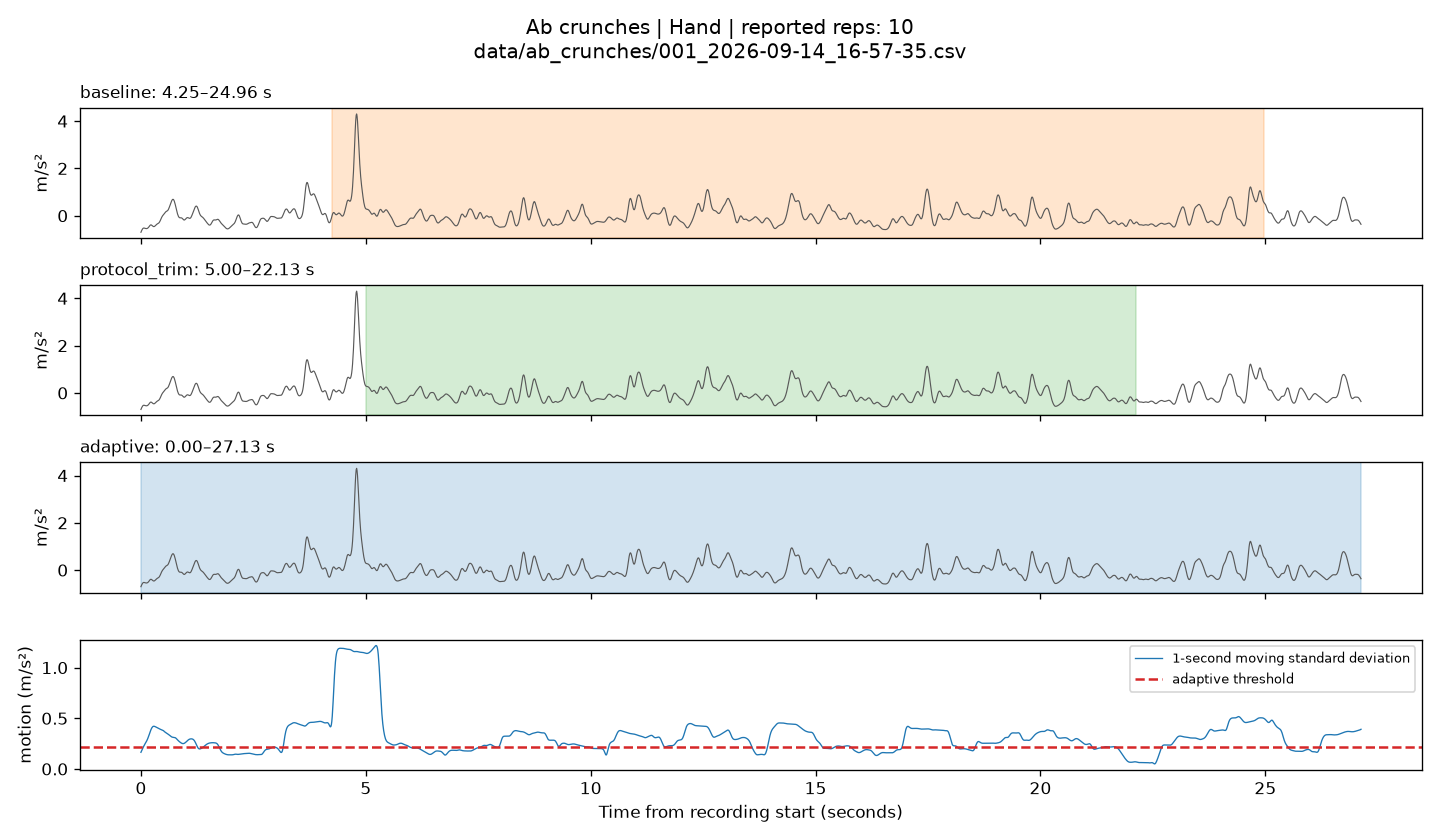

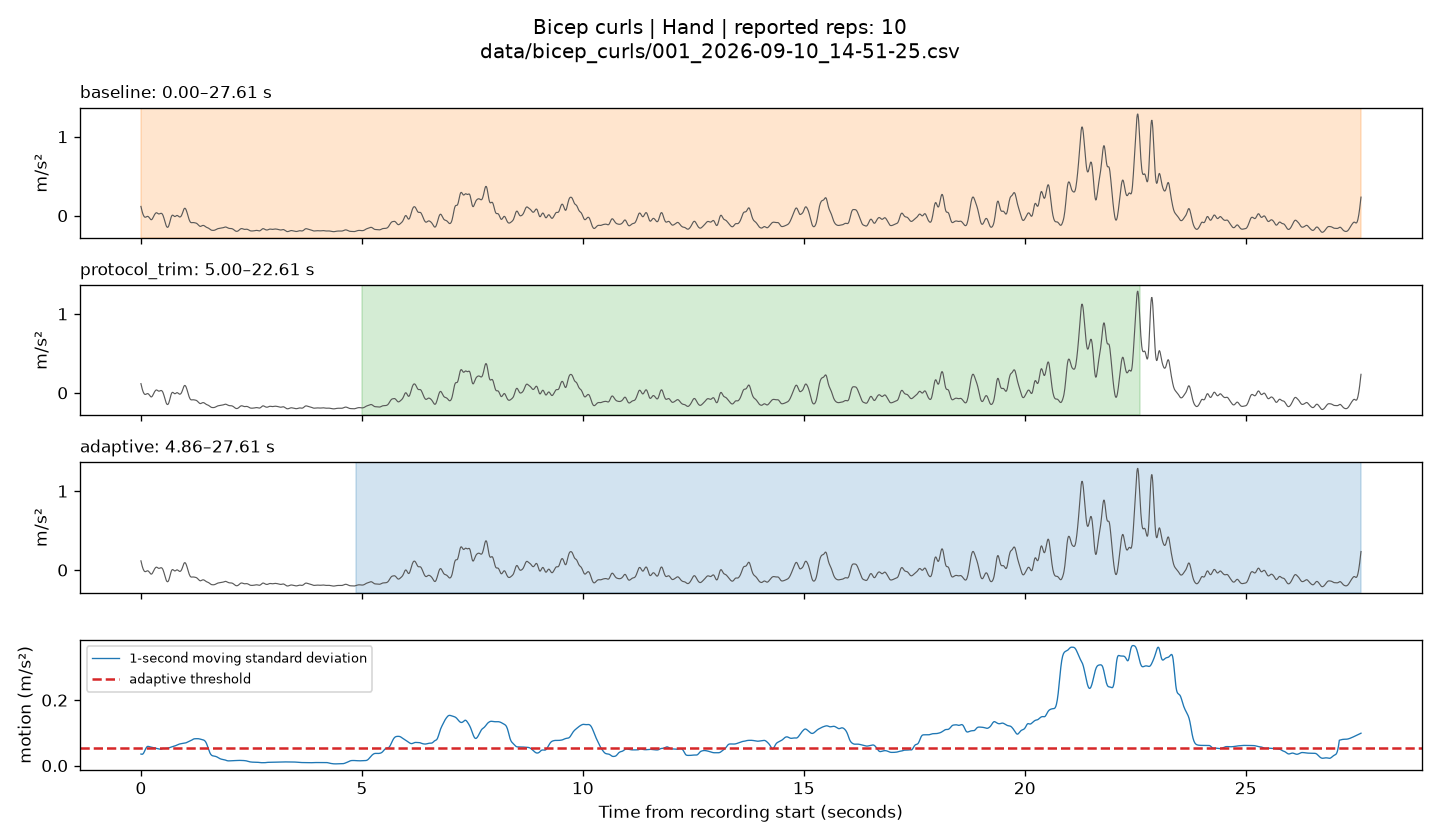

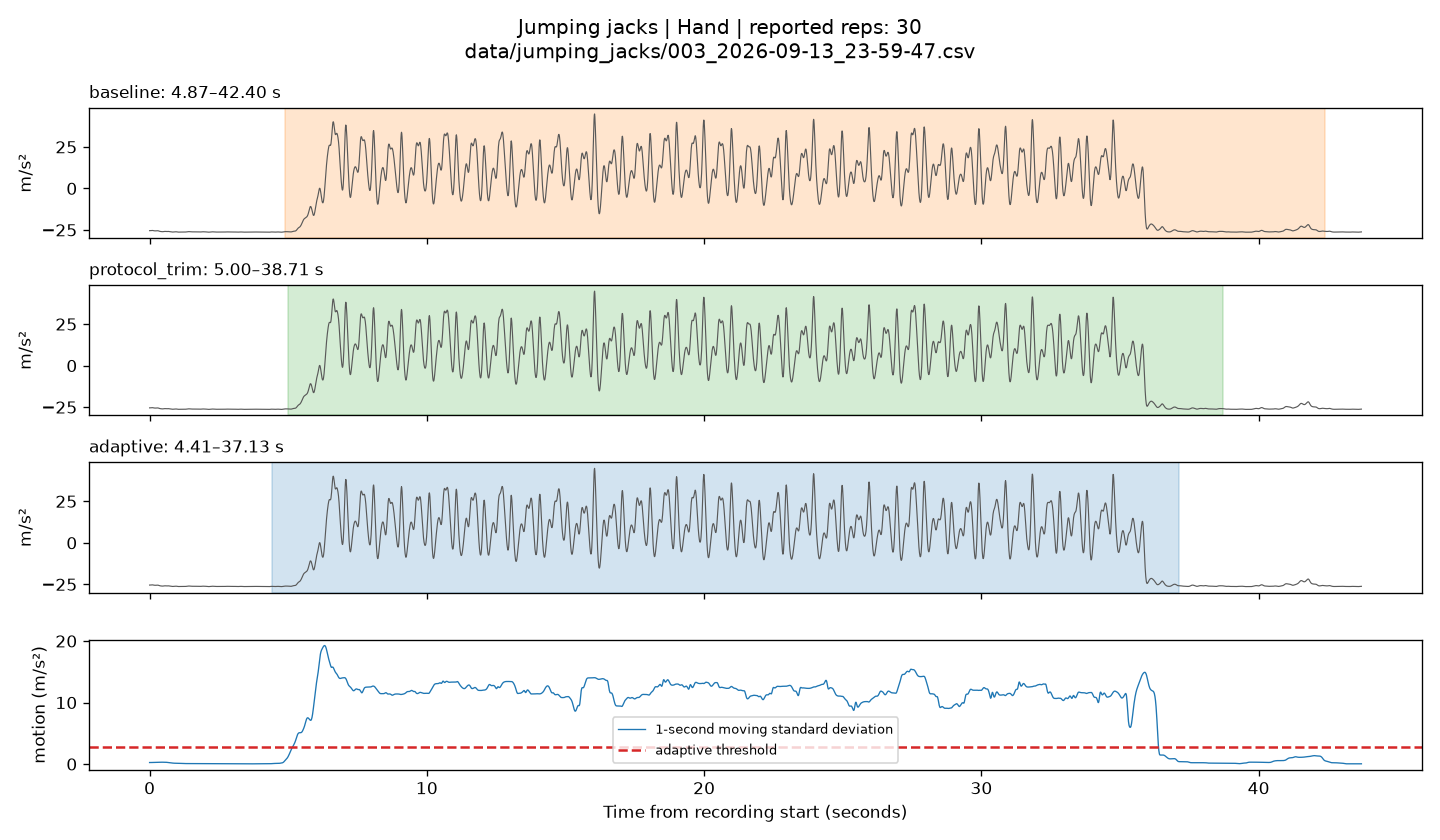

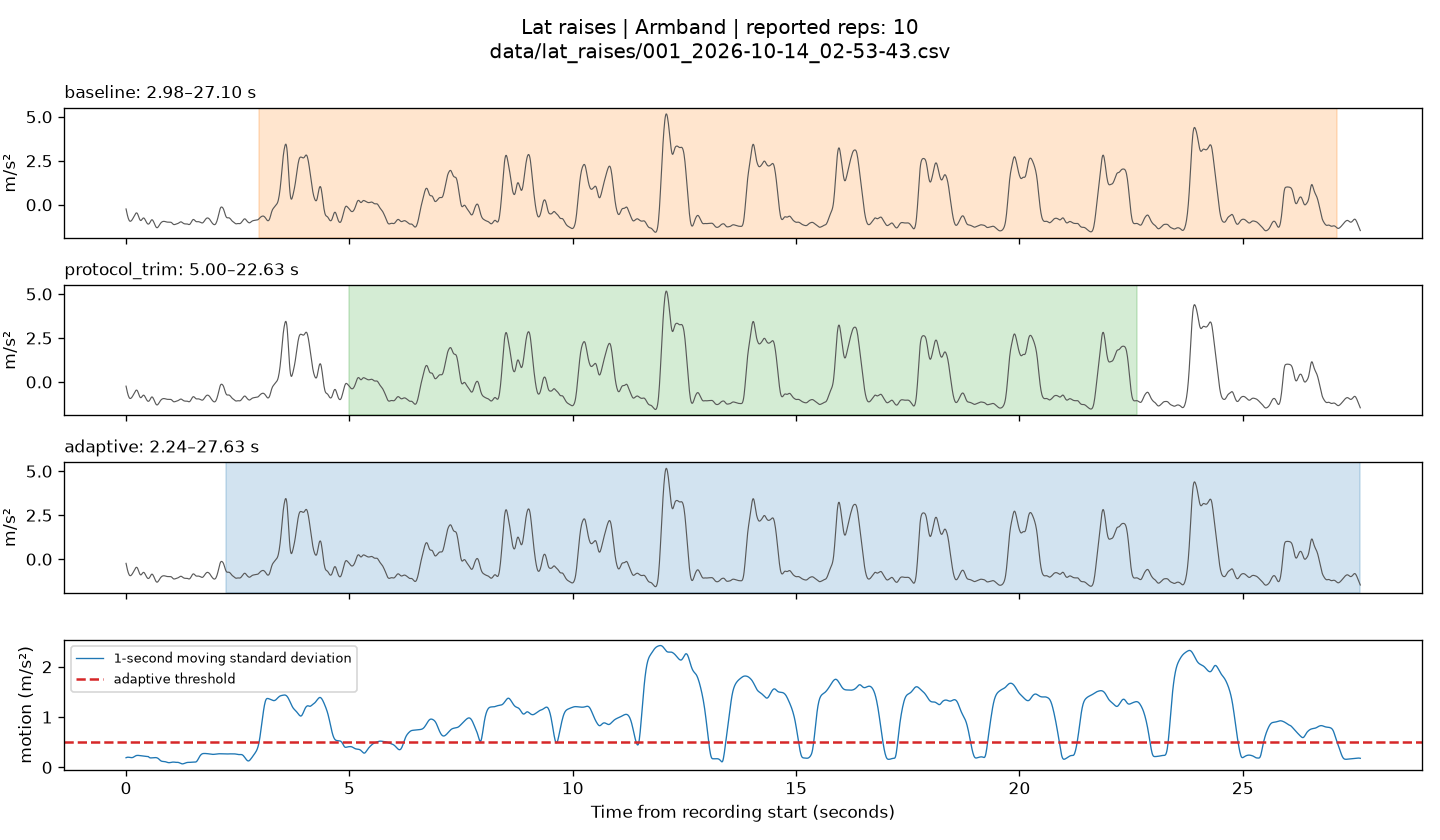

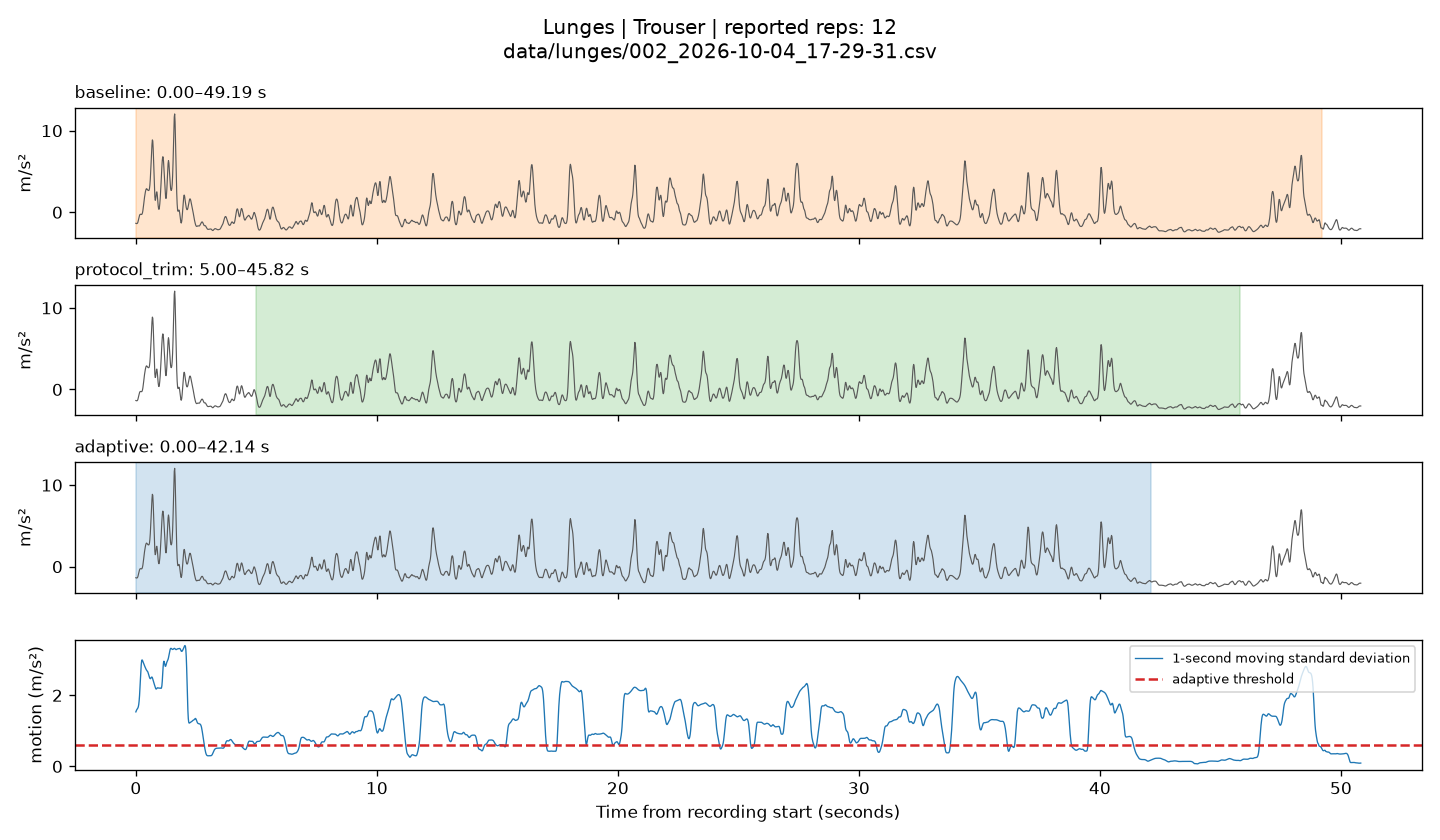

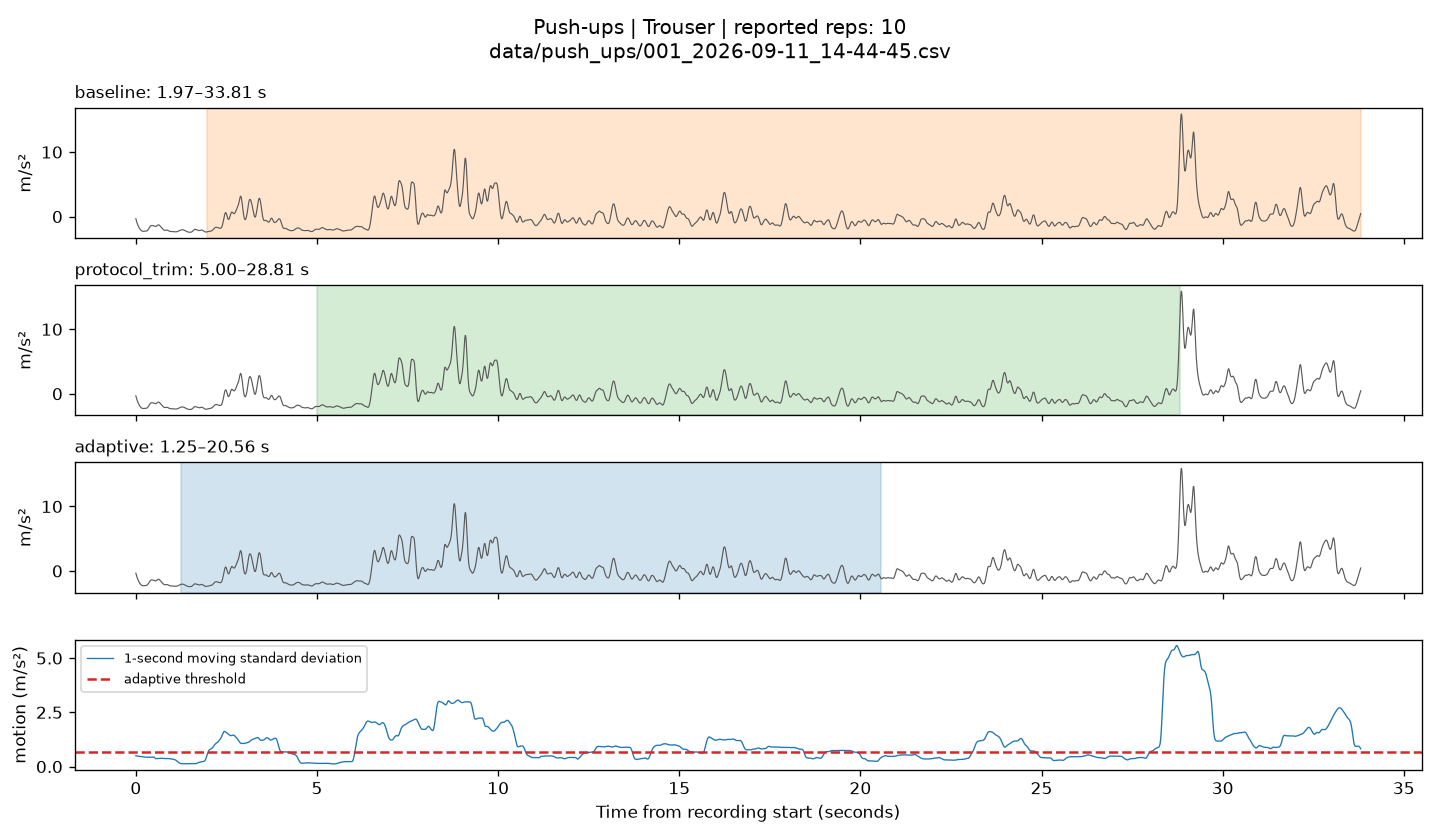

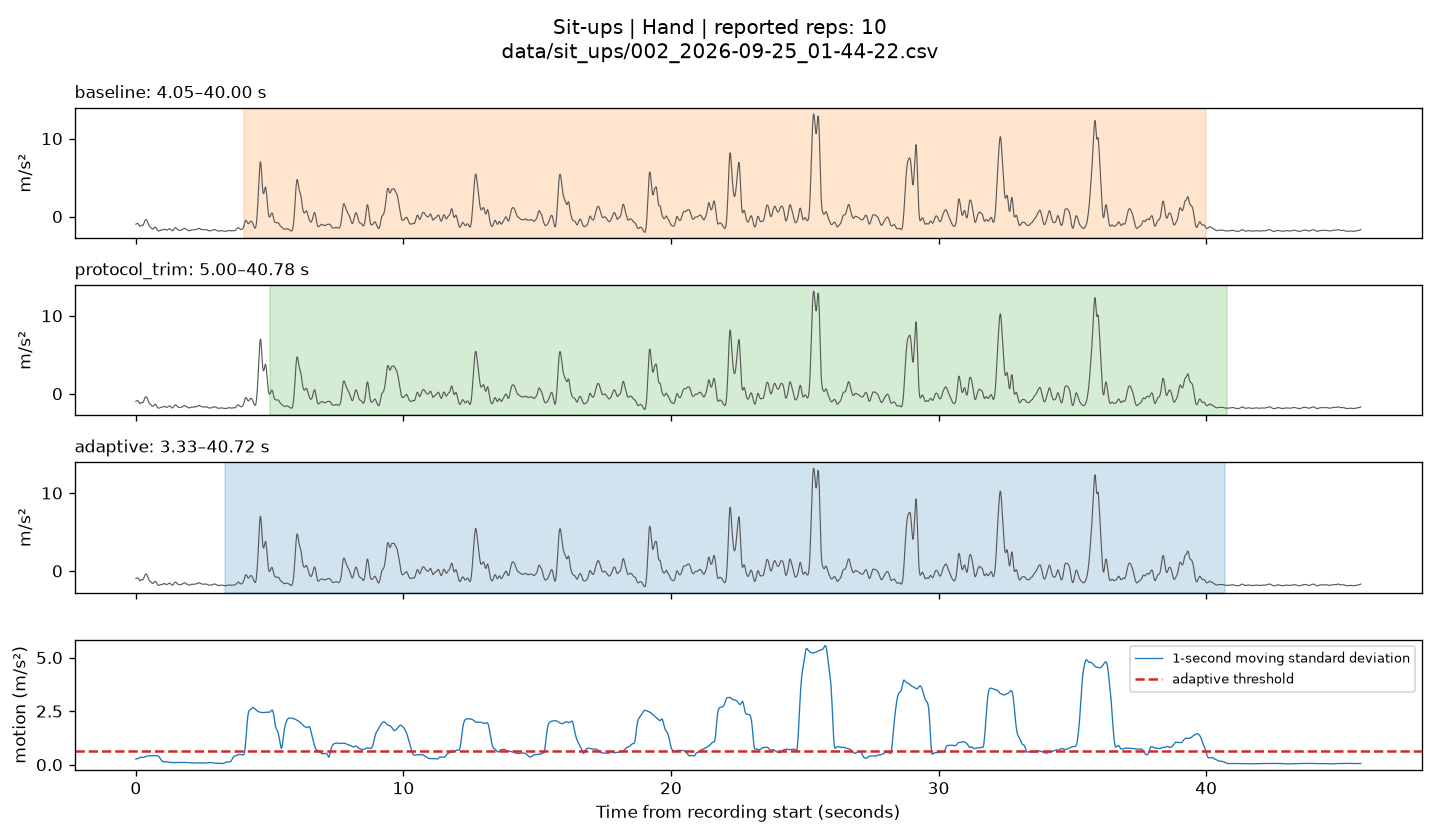

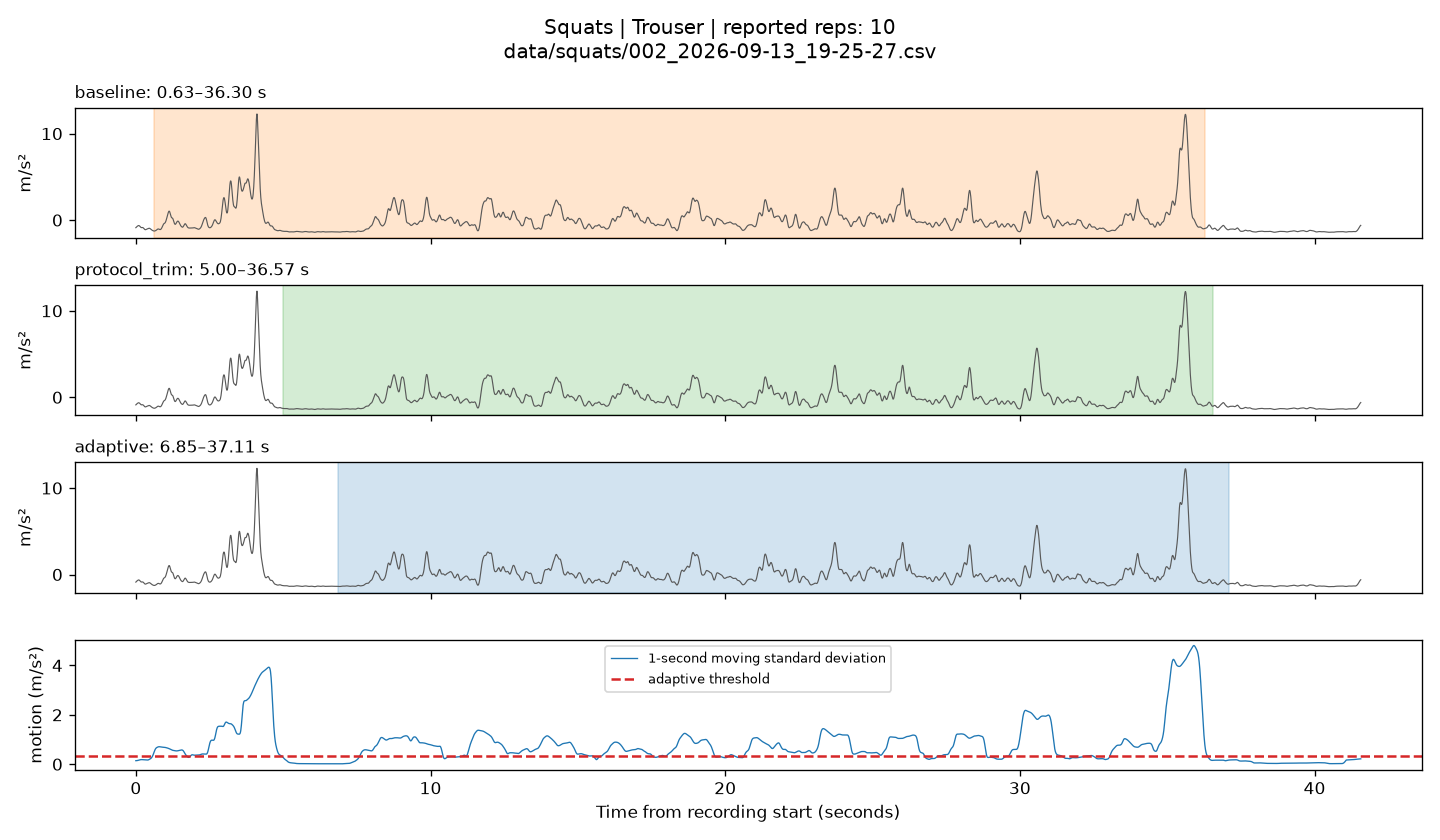

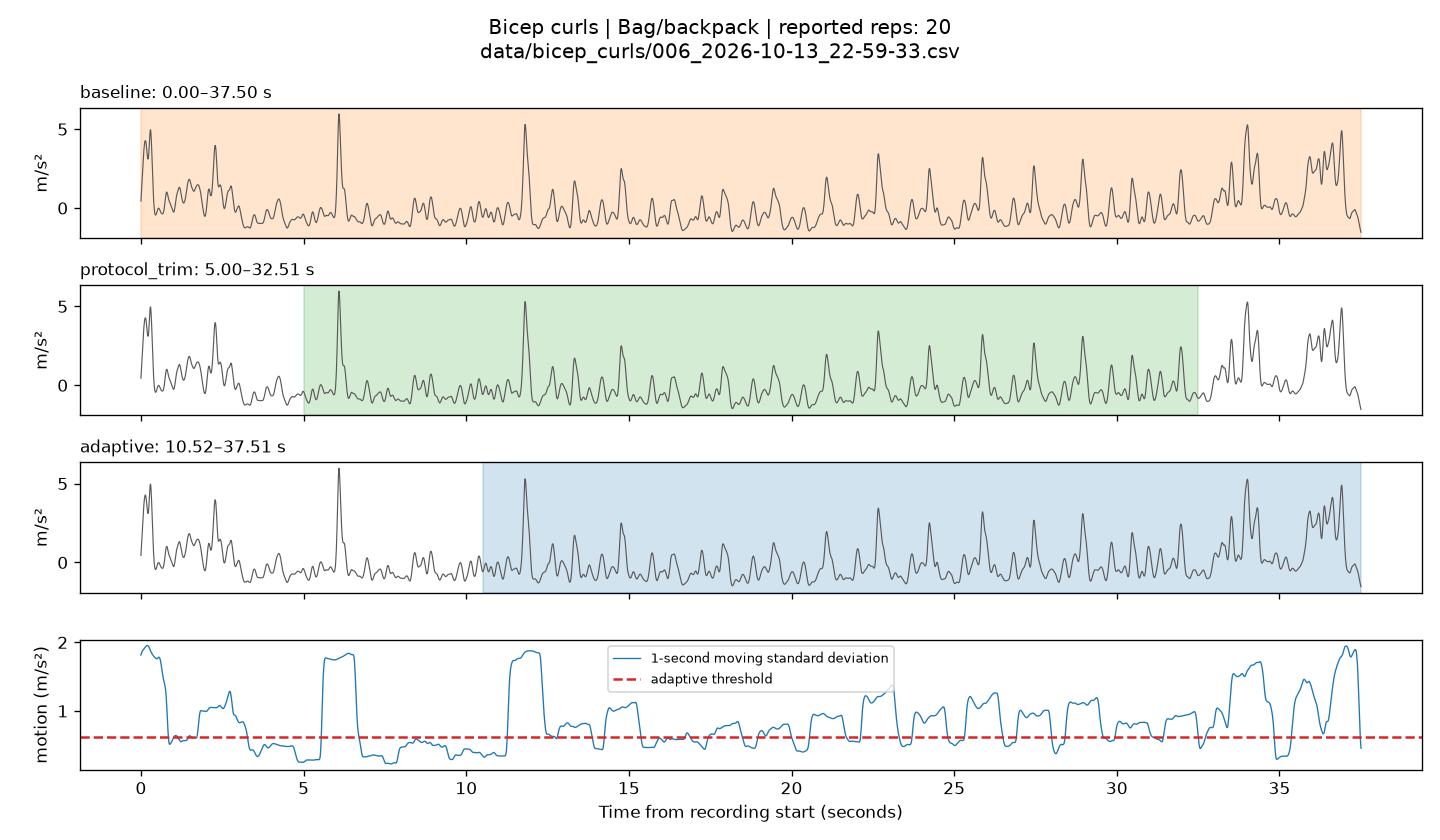

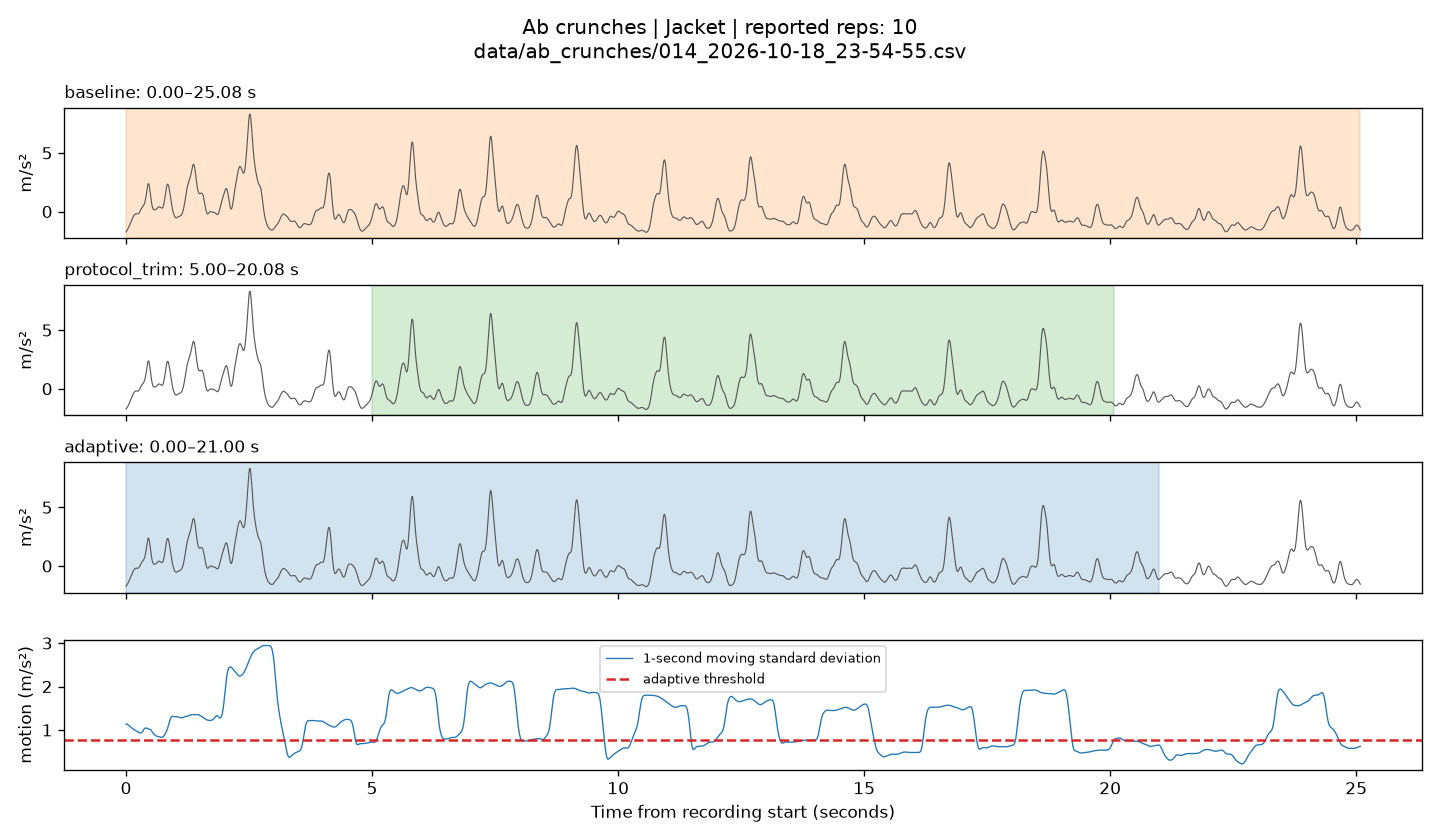

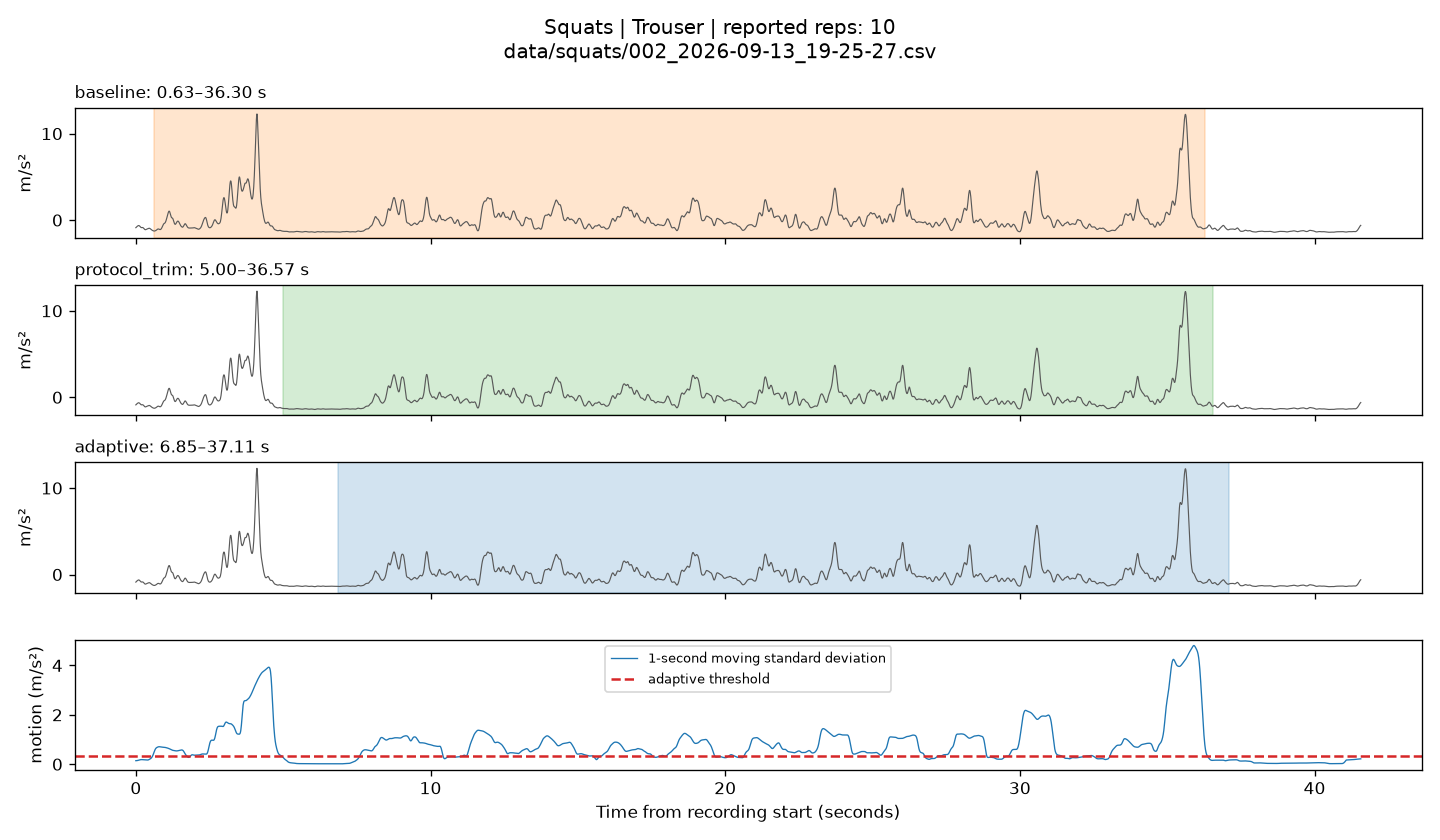

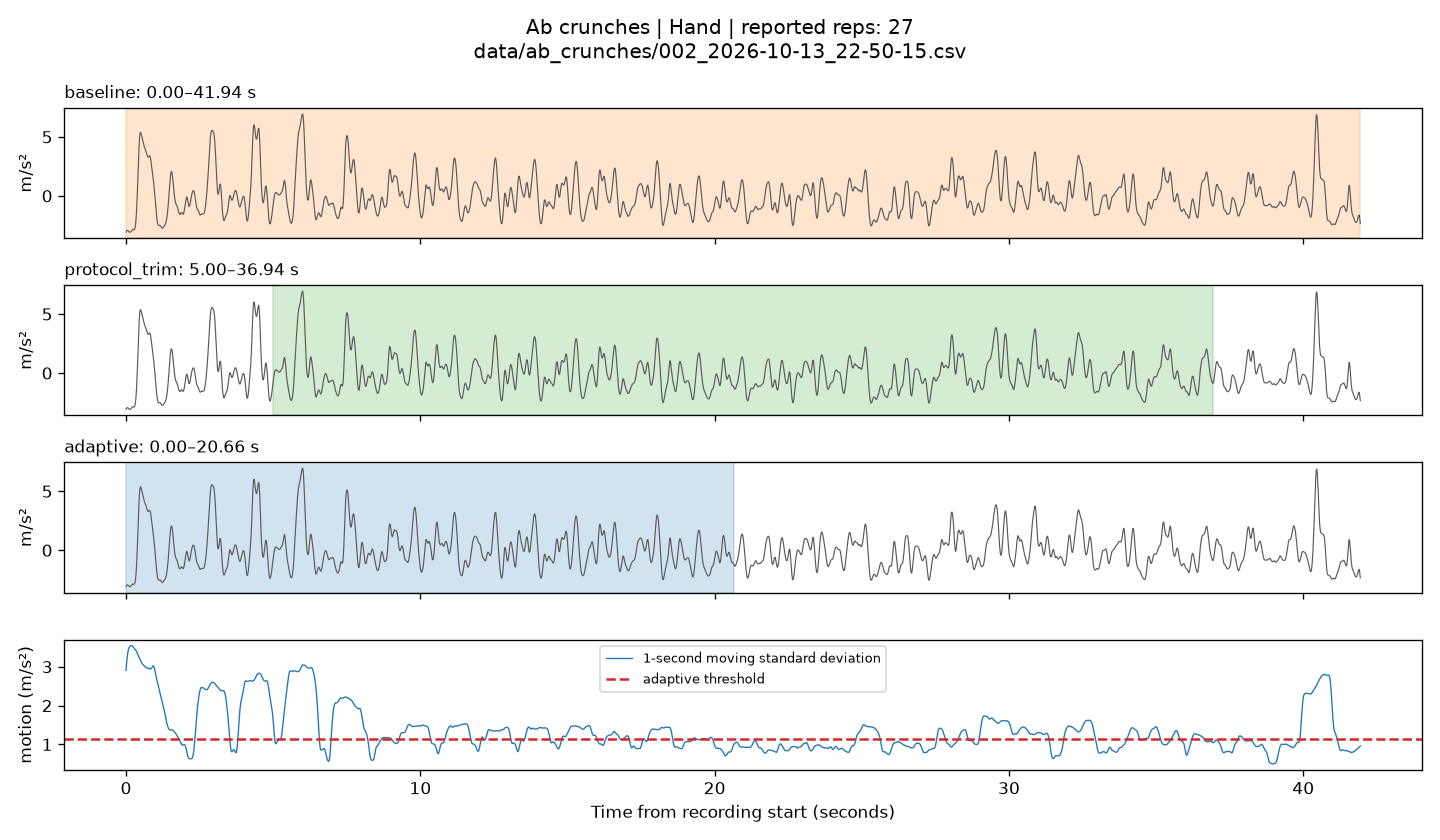

In [5]:
# Reproduce Step 2 and display fit examples; test recordings are not evaluated.
segmentation_results = run_segmentation_exploration()

print("Counting comparison on validation, with the unchanged baseline counter:")
segmentation_counting = pd.DataFrame(segmentation_results['counting'])
display(segmentation_counting[segmentation_counting['split'] == 'validation'].round(4))
print("Classification comparison on validation windows:")
display(pd.DataFrame(segmentation_results['classification']).round(4))

# Ten fit examples cover every exercise and placement; two illustrate failures.
for path in segmentation_results['visual_examples']:
    display(Image(filename=path))
for name, example in segmentation_results['failure_examples'].items():
    print(name, example['recording'])
    display(Image(filename=example['figure']))


#### Segmentation interpretation

The baseline keeps everything from the first to last threshold crossing, so
short handling bursts can extend the segment. The adaptive method instead keeps
the longest sustained motion bout. It can remove isolated handling, but it still
keeps handling close to a set and can cut a set when pauses split it into bouts.

Five-second trimming assumes people followed the collection protocol. It can
remove genuine reps when the person did not stand still for five seconds.

Full development metrics, specific failures, and our decision are recorded in
`WORK_LOG.md`. These comparisons use the baseline counter and baseline features;
we must repeat the required final comparisons with the final counter/features
and the reserved test recordings later.

With the counter unchanged, adaptive segmentation reduces validation MAE from
**7.99 to 5.95 reps**; fixed trimming gives **6.01**. Both alternatives count
**21.05%** of validation recordings within two reps, versus **14.47%** for baseline.
With adaptive segmentation, Decision Tree window accuracy is **49.94%** and
Random Forest accuracy **48.93%**, versus **41.87%** and **46.80%** at baseline.
Changing segmentation changes which windows are evaluated, so the accuracy
comparison does not use identical windows.

- **Baseline failure:** squats `002_2026-09-13_19-25-27.csv` (Trouser). The baseline
  keeps an initial burst before the main repeated movement. Adaptive excludes it
  but still keeps a final burst; counts change from 19 to 16 against 10 reported.
- **Our failure:** ab crunches `002_2026-10-13_22-50-15.csv` (Hand). Falling motion
  amplitude splits the set; adaptive keeps only 0–20.66 seconds of the roughly
  42-second trace. Counts change from 29 to 14 against 27 reported.

We keep adaptive as the working method for development, while preserving the
alternatives for the final comparison. It is not a proven winner over fixed
trimming, and the final counter may change the ranking.


###  Assignment: Function 2: count_reps(data, sample_rate, exercise)

**Instructions:**
Define the `count_reps` function that counts the reps in one set. This is the **rep counting** axis in RUBRIC.md (exploration report §3).

- The function takes as arguments:
  - `data`: the **segment** only (already cut with the segmentation), with the same columns as above
  - `sample_rate`: the sampling frequency of the recording
  - `exercise`: the exercise name from the manifest (e.g., `'Squats'`), so you can use exercise-specific settings
- The function returns the number of reps (an integer).

**Hints and Instructions:**
- As provided, the function returns the baseline count (A1-style peaks on `filtered_accel_mag`). It counts far too many reps: for many exercises the magnitude has two peaks per rep, and noise adds more.
- Ideas to try:
  - **Pick a better signal**: one axis (e.g., the one with the largest std in the segment), or the direction that moves the most (the first principal component of `x`, `y`, `z`, e.g., with `np.linalg.svd`).
  - **Low-pass harder**: reps are slow, one every 1-4 s (0.25-1 Hz). A cutoff around 1-1.5 Hz removes most of the extra peaks.
  - **Minimum distance between peaks**: set `distance` in `find_peaks` from the rep period. You can estimate the period with the autocorrelation of the signal, or use the typical time per rep of each exercise in the training recordings (segment length / reps).
  - **Prominence**: set `prominence` relative to the std of the signal, so small bumps are not counted.
  - **Exercise-specific settings**: e.g., the typical time per rep is different for each exercise.
  - **Placement effects**: `count_reps` does not get the placement. E.g., with the phone in a pocket, a jumping jack has two jumps (feet out, feet in) per rep. A low-pass filter around 1 Hz mostly merges them into one cycle per rep.
- Tune on the training recordings only (fit + validation), never on test.

In [6]:
def count_reps(data, sample_rate, exercise):
    # Smoothed PCA signal with distance/prominence peak detection.
    # Settings are selected on fit recordings in rep_counting_exploration.py.
    return improved_count_reps(data, sample_rate, exercise)


## Assignment-Rep Counting: Evaluate Segmentation and Rep Counting

`evaluate_rep_counter(manifest, segment_fn, count_fn)` runs a segmentation and a rep counter on every recording of `manifest` (using the true exercise from the manifest), and `rep_metrics` summarizes the errors.

1. **Baseline**: evaluate `baseline_segment` + `baseline_count_reps` on the training recordings (`train_manifest`).

2. **Tune**: improve `count_reps` and `find_exercise_segment` on the training recordings. Use `rep_metrics(results, by='exercise')` and `rep_metrics(results, by='placement')` to see where the errors are, and `bias` to see if you count too many or too few.

3. **Test**: when you are done tuning, evaluate each combination in the table below on `test_manifest` (`no_segment` = the whole recording). For §1 of your report, also evaluate the other segmentation approaches you tried, with your rep counter.

4. **Fill up** these tables.

5. **Interpretation of the results**: How much did segmentation help, and how much did the rep counter help? Which exercises and placements are hardest to count, and why?

Fit signal/cutoff choice: pca_1Hz
Fit-selected counter: pca_1Hz_distance0.6_prom1; settings frozen before validation
                    counter      split  recordings      MAE  within_2      bias
                   baseline        fit         225 6.360000  0.280000  1.248889
                   baseline validation          76 5.947368  0.210526  1.394737
              magnitude_1Hz        fit         225 6.613333  0.302222 -2.400000
              magnitude_1Hz validation          76 6.105263  0.315789 -1.631579
            magnitude_1.5Hz        fit         225 7.475556  0.280000  2.515556
            magnitude_1.5Hz validation          76 6.986842  0.171053  3.328947
                   axis_1Hz        fit         225 5.733333  0.404444  1.128889
                   axis_1Hz validation          76 3.881579  0.473684  0.855263
                 axis_1.5Hz        fit         225 7.626667  0.311111  4.186667
                 axis_1.5Hz validation          76 6.131579  0.368421  4.000000
   

,counter,split,recordings,MAE,within_2,bias
0,baseline,fit,225,6.3600,0.2800,1.2489
1,baseline,validation,76,5.9474,0.2105,1.3947
2,magnitude_1Hz,fit,225,6.6133,0.3022,-2.4000
3,magnitude_1Hz,validation,76,6.1053,0.3158,-1.6316
4,magnitude_1.5Hz,fit,225,7.4756,0.2800,2.5156
5,magnitude_1.5Hz,validation,76,6.9868,0.1711,3.3289
6,axis_1Hz,fit,225,5.7333,0.4044,1.1289
7,axis_1Hz,validation,76,3.8816,0.4737,0.8553
8,axis_1.5Hz,fit,225,7.6267,0.3111,4.1867
9,axis_1.5Hz,validation,76,6.1316,0.3684,4.0000


,segmentation,counter,split,recordings,MAE,within_2,bias
2,none,baseline,validation,76,7.9342,0.1447,4.6184
5,baseline,baseline,validation,76,7.9868,0.1447,4.0395
8,adaptive,baseline,validation,76,5.9474,0.2105,1.3947
11,baseline,ours,validation,76,5.1447,0.4474,-0.1184
14,adaptive,ours,validation,76,3.3289,0.5658,-1.5132
17,protocol_trim,ours,validation,76,3.6579,0.4868,-1.1316


,recordings,MAE,within_2,bias
exercise,,,,
Ab crunches,5,4.20,0.40,-1.80
Bicep curls,9,3.89,0.67,-3.44
Jumping jacks,16,3.88,0.62,-3.75
Lat raises,3,4.67,0.33,-4.67
Lunges,7,1.86,0.71,1.29
Push-ups,10,3.50,0.40,-0.70
Sit-ups,7,4.14,0.29,-3.86
Squats,19,2.32,0.68,1.26


,recordings,MAE,within_2,bias
placement,,,,
Armband,1,8.00,0.00,-8.00
Bag/backpack,2,4.50,0.50,-4.50
Hand,39,3.13,0.64,-1.18
Jacket,1,4.00,0.00,4.00
Trouser,33,3.33,0.52,-1.70


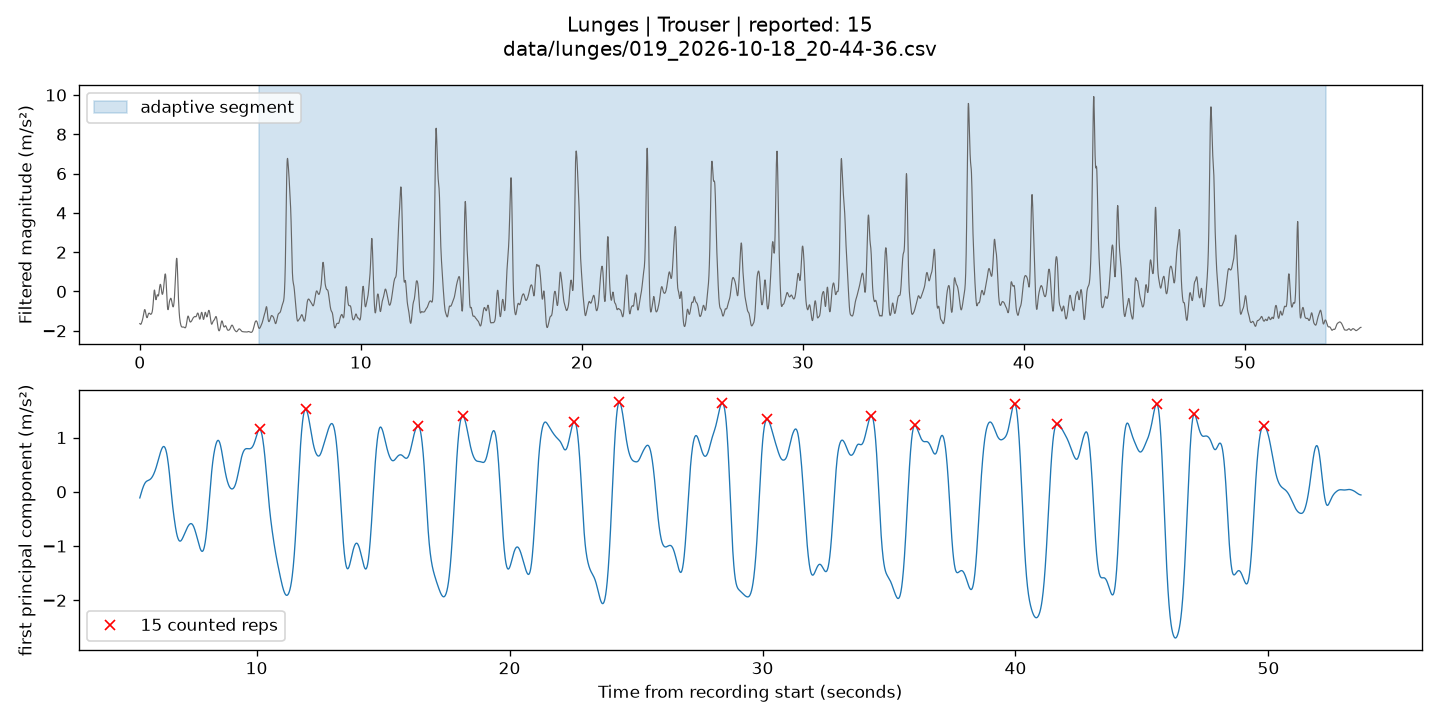

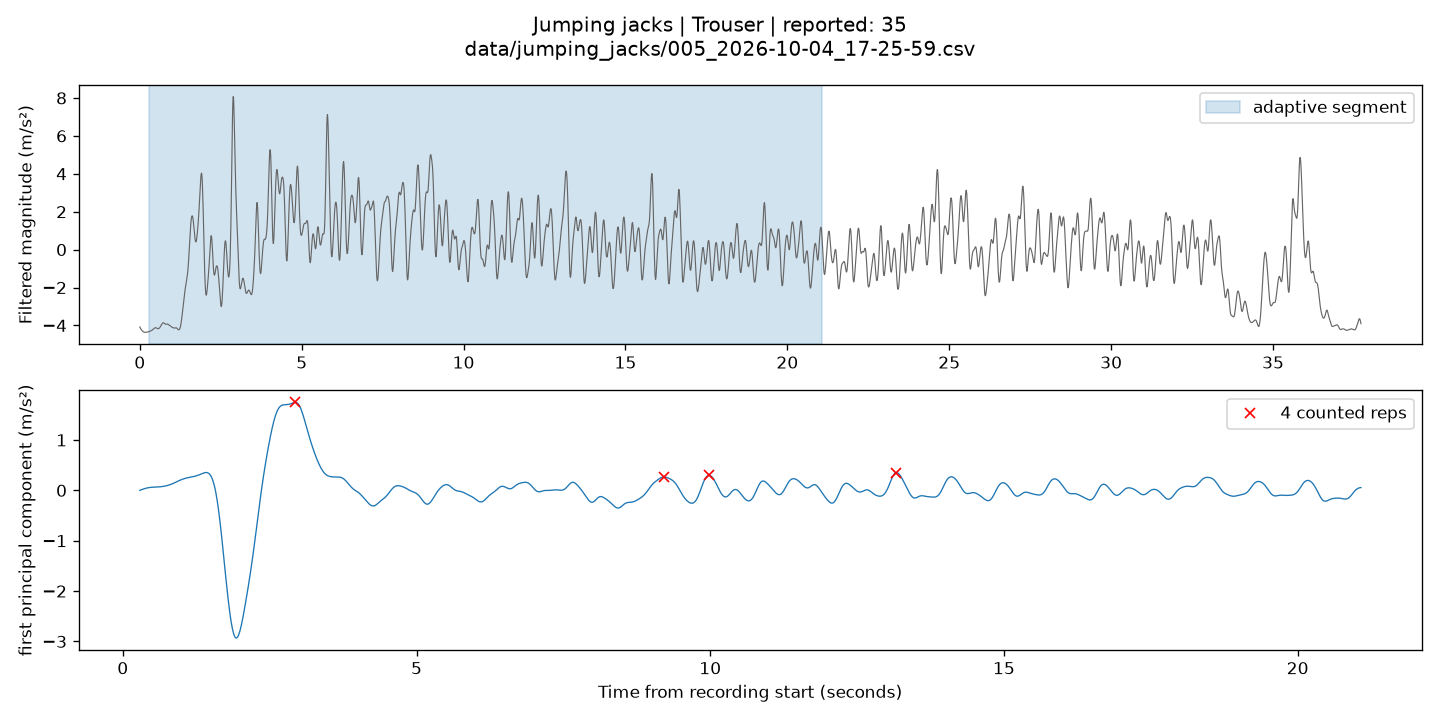

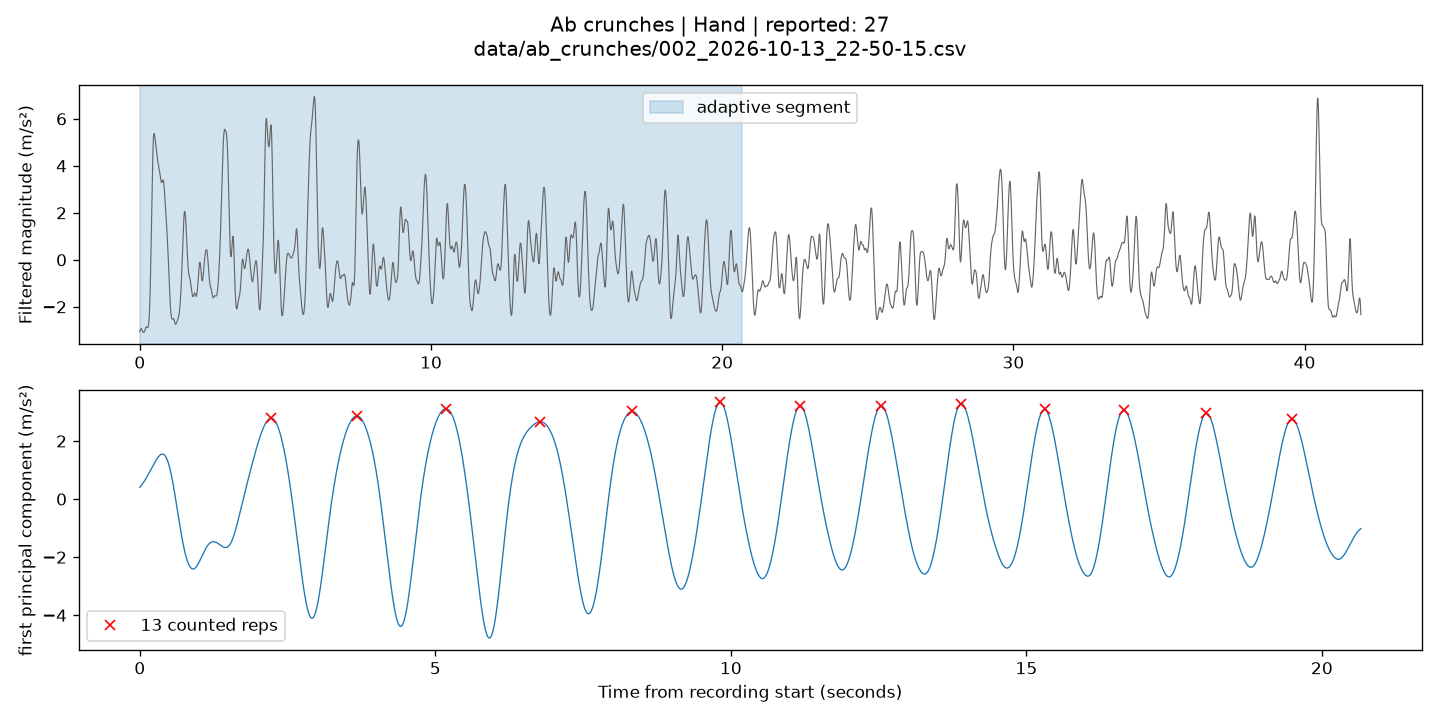

In [7]:
# Step 3: choose settings on fit recordings, then measure on validation.
# The script preserves all comparisons under results/step3_rep_counting/.
rep_exploration = run_rep_counting_exploration()

print("Counter comparison with adaptive segmentation (within_2 is a fraction):")
counter_comparison = pd.DataFrame(rep_exploration['counter_comparison'])
display(counter_comparison.round(4))
print("Selected settings (chosen by fit MAE, before validation):")
print(rep_exploration['selected_settings'])

print("Segmentation/counter combinations on validation recordings:")
rep_combinations = pd.DataFrame(rep_exploration['segmentation_counter_comparison'])
display(rep_combinations[rep_combinations['split'] == 'validation'].round(4))

rep_results = pd.read_csv('results/step3_rep_counting/combination_adaptive_ours_train.csv')
validation_rep_results = rep_results[rep_results['recording'].isin(val_manifest['path'])]
print("Our counter + adaptive segmentation, validation errors by exercise:")
display(rep_metrics(validation_rep_results, by='exercise'))
print("Validation errors by placement:")
display(rep_metrics(validation_rep_results, by='placement'))

# Show the actual counted signal and exact detected peaks, using fit examples.
for name, example in rep_exploration['figures'].items():
    print(name, example['recording'])
    display(Image(filename=example['figure']))


**For the test recordings:**

| Segmentation | Rep counter | MAE (reps) | Within ±2 reps | Bias |
|-|-|-|-|-|
| none (`no_segment`) | baseline | **FILL UP** | **FILL UP** | **FILL UP** |
| baseline | baseline | **FILL UP** | **FILL UP** | **FILL UP** |
| yours | baseline | **FILL UP** | **FILL UP** | **FILL UP** |
| baseline | yours | **FILL UP** | **FILL UP** | **FILL UP** |
| yours | yours | **FILL UP** | **FILL UP** | **FILL UP** |

**Your segmentation + your rep counter, by placement (test recordings):**

| Placement | Recordings | MAE (reps) | Within ±2 reps |
|-|-|-|-|
| Hand | **FILL UP** | **FILL UP** | **FILL UP** |
| Trouser | **FILL UP** | **FILL UP** | **FILL UP** |
| Jacket | **FILL UP** | **FILL UP** | **FILL UP** |
| Armband | **FILL UP** | **FILL UP** | **FILL UP** |


#### 🛑 Interpretation of the results

These final-test tables are intentionally pending. The development comparison
above uses fit/validation recordings; we will fill the required test numbers
when the final pipeline is fixed.

**Step 3 development findings:** With adaptive segmentation fixed, our selected
PCA counter lowers validation MAE from **5.95 to 3.33 reps**, and increases the
share within two reps from **21.05% to 56.58%**. Settings were selected by fit MAE:
1 Hz low-pass, minimum peak distance 0.6 seconds, and prominence of 1.0 times
signal standard deviation. One setting is used for all exercises and placements.

Both segmentation and counting help: baseline segmentation + our counter gives
validation MAE **5.14**, while adaptive + our counter gives **3.33**. Protocol
trimming + our counter gives **3.66**, a small difference on 76 recordings.
Our counter now undercounts overall (validation bias **-1.51**).

Lunges and squats improve substantially; weak upper-body motion and fast jumping
jacks still fail. Small placement groups make broad placement claims unreliable.
In the illustrated lunges recording, magnitude counts 32 versus PCA's 15, matching
15 reported reps. In the illustrated ab-crunch recording, adaptive cuts half the
set: our counter gets 13 on that interval but 27 with baseline segmentation,
matching the report. This error starts in segmentation. The jumping-jack example
also suffers from lost activity and smoothed-away motion.

See `WORK_LOG.md` for the complete experiment record and limits. Predictions,
settings, and figures are saved under `results/step3_rep_counting/`.


###  Assignment: Function 3: add_my_features(window, sample_rate)

This is where you do your **feature engineering** (exploration report §2). The function receives one window and returns a one-row DataFrame of features.

**Hints and Instructions:**
- The window has the columns `time`, `x`, `y`, `z`, `accel_mag`, and `filtered_accel_mag`.
- Start from the baseline features in `add_features` (7 statistics of the filtered magnitude, from A2) and add your own as new columns. As provided, the function only returns the baseline, so you can run the whole notebook before writing any features.
- Ideas to try:
  - **Which axis moves**: std of `x`, `y`, `z`, and the share of the largest one (a bicep curl in the hand moves mostly along one axis; a jumping jack moves along all of them)
  - **Rep rate**: dominant frequency of the filtered magnitude or of one axis (use `np.fft.rfft` and `np.fft.rfftfreq(len(signal), 1/sample_rate)`). Jumping jacks are fast, squats are slow
  - **Correlation between axes**: `np.corrcoef`
  - **Intensity**: RMS, range, number of peaks per second
- Gravity is removed, so the features cannot directly tell lying down (sit-ups) from standing (squats).
- Some features can be `NaN` (e.g., the correlation of a flat window). Return 0 instead, because most models cannot handle `NaN`.
- Aim for ~5-10 features of your own on top of the 7 baseline features. Keep the ones that help and document the ones you dropped.

In [8]:
def add_my_features(window, sample_rate):
    # Seven baseline features plus nine selected additions. See features.py.
    # Feature groups and omissions were compared on validation, not test.
    return selected_window_features(window, sample_rate)


#### Helper functions (provided)

`train_decision_tree`, `train_random_forest`, and `evaluate` take an optional `features` argument (a list of column names). By default, the training functions use every feature column (everything except `exercise` and `recording`), and `evaluate` uses the same columns the model was trained on. Unlike A2, the training functions do not split the data. You pass them the training windows, and then you evaluate on other recordings with `evaluate`.

Use `train_random_forest` (fixed settings) to compare window lengths, features, and segmentation. Use `train_decision_tree` in Classification1.

In [9]:
BASELINE_FEATURES = ['avg', 'max', 'med', 'min', 'q25', 'q75', 'std']

def feature_columns(frames):
    return [c for c in frames.columns if c not in ('exercise', 'recording')]


def evaluate(model, frames, features=None, verbose=True):
    # By default, use the same columns the model was trained on
    if features is None:
        features = getattr(model, 'feature_names_in_', feature_columns(frames))
    X_test = frames[list(features)]

    # Extract target column
    y_test = frames['exercise']

    pred = model.predict(X_test)
    acc = accuracy_score(y_test, pred)
    if verbose:
        print(classification_report(y_test, pred, zero_division=0))
        print("Accuracy:", acc)
    return acc, pred

In [10]:
def train_decision_tree(frames, max_depth=5, criterion='entropy', features=None):
    # Extract feature columns
    if features is None:
        features = feature_columns(frames)
    X = frames[list(features)]

    # Extract target column
    y = frames['exercise']

    # Create and train the model on all the windows in frames
    dt_model = DecisionTreeClassifier(criterion=criterion, max_depth=max_depth, random_state=42).fit(X, y)
    return dt_model


def train_random_forest(frames, features=None):
    # Extract feature columns
    if features is None:
        features = feature_columns(frames)
    X = frames[list(features)]

    # Extract target column
    y = frames['exercise']

    # A random forest with fixed settings, to compare window lengths, features, and segmentation
    rf_model = RandomForestClassifier(n_estimators=100, random_state=42).fit(X, y)
    return rf_model

## Step 1: Supplied baselines

`baseline.py` reproduces the provided segmentation and rep counter on training
recordings. It trains the default Decision Tree and Random Forest on fit
recordings and measures validation window accuracy, using the seven baseline
features and a 4-second starting window with 50% overlap. No test predictions.

Settings, predictions, and tables are saved in `results/step1_baseline/`.
The Step 2 and Step 3 experiments have their own separate results folders.
See `WORK_LOG.md` for explanations, limitations, and the current project structure.


In [11]:
baseline_results = run_baseline()

print("Baseline counting (within_2 is a fraction; bias = counted minus reported):")
display(pd.DataFrame(baseline_results['rep_counting']).T.round(4))
print("Baseline classification on validation windows:")
display(pd.DataFrame(baseline_results['classification'])[
    ['model', 'fit_windows', 'validation_windows', 'validation_window_accuracy']
].round(4))


Recordings: {'train': 301, 'fit': 225, 'validation': 76, 'test': 129}
Counting repetitions on the 301 training recordings...
Building baseline features for training recordings only...
Fitting Decision Tree; evaluating validation windows...
Fitting Random Forest; evaluating validation windows...
Training rep metrics: {'recordings': 301, 'MAE': 7.980066445182724, 'within_2': 0.19601328903654486, 'bias': 4.6112956810631225}
Decision Tree validation window accuracy: 41.87%
Random Forest validation window accuracy: 46.80%
Results saved in results/step1_baseline
Baseline counting (within_2 is a fraction; bias = counted minus reported):
Baseline classification on validation windows:


,recordings,MAE,within_2,bias
train,301.0,7.9801,0.1960,4.6113
fit,225.0,7.9778,0.2133,4.8044
validation,76.0,7.9868,0.1447,4.0395


,model,fit_windows,validation_windows,validation_window_accuracy
0,Decision Tree,3677,1156,0.4187
1,Random Forest,3677,1156,0.4680


### What the Step 1 results mean

With the supplied methods, training repetition-count MAE is **7.98 reps**,
**19.60%** of recordings are within two reps, and bias is **+4.61 reps**.
The counter overcounts overall, but jumping jacks are undercounted on average.
We need to inspect traces before attributing those errors to a particular cause.

On the 76 validation recordings (1,156 windows), the default Decision Tree
reaches **41.87%** window accuracy and the default Random Forest **46.80%**.
These are starting measurements, not tuned results or final test scores.

The full breakdowns, limitations, and reproduction commands are recorded in
`WORK_LOG.md`. These remain our unchanged starting-point comparisons.


## Assignment-Feature Exploration: Window Length, Features, and Segmentation

Before comparing models, choose the window length and the feature set (exploration report §2), and check the effect of your segmentation on classification (§1). Train with `train_random_forest` on the **fit** windows and evaluate on the **validation** windows. We use a random forest here because it uses many features at once, so the effect of a feature set is easier to see than with a small decision tree.

`build_feature_frames` goes over all 430 recordings (about 1-2 minutes). Build it once per setting for the whole `manifest`, then use `select_recordings` to get the fit, validation, and test windows.

1. **Window length**: Build the feature frames with at least three window lengths (e.g., 2 s, 4 s, 6 s), using `find_exercise_segment` and the baseline features (`baseline_features`). Train on fit, evaluate on validation.

2. **Features**: Write `add_my_features` (Function 3) and rebuild. Compare the baseline features to your features at the same window length. Try adding and removing features (pass `features=[...]` to `train_random_forest`) and use the classification report to see which exercises each feature helps.

3. **Segmentation**: Rebuild with your features and `no_segment` instead of `find_exercise_segment`, and compare.

4. **Lock in** one window length, one feature set, and one segmentation, and use them in all the sections below.

5. **Fill up** this table.

6. **Interpretation of the results**: Which window length worked best, and why do you think so? Which features helped, and which exercises did they separate? Did segmentation help the classifier?

Building 2s windows, adaptive segmentation...
window_2s_baseline: 47.62%
Building 4s windows, adaptive segmentation...
window_4s_baseline: 48.93%
Building 6s windows, adaptive segmentation...
window_6s_baseline: 50.09%
Chosen baseline-feature window: 6s
features_baseline: 50.09%
features_axis_motion: 52.09%
features_rhythm: 50.09%
features_correlation: 53.54%
features_intensity: 49.00%
features_axis_rhythm: 55.35%
features_axis_correlation: 55.17%
features_axis_rhythm_correlation: 53.18%
features_axis_rhythm_intensity: 55.35%
features_all: 54.45%
features_without_std_x: 55.17%
features_without_std_y: 52.99%
features_without_std_z: 55.17%
features_without_axis_dominance: 54.45%
features_without_dominant_frequency: 56.08%
features_without_spectral_concentration: 54.99%
features_without_corr_xy: 52.63%
features_without_corr_xz: 56.26%
features_without_corr_yz: 55.35%
features_without_rms_acceleration: 53.18%
Chosen feature set: without_corr_xz
segmentation_adaptive: 56.26%
Building 6s win

,window_sec,fit_windows,validation_windows,validation_window_accuracy
0,2,5686,1894,0.4762
1,4,2670,887,0.4893
2,6,1674,551,0.5009


,run,feature_count,validation_window_accuracy
0,features_baseline,7,0.5009
1,features_axis_motion,11,0.5209
2,features_rhythm,9,0.5009
3,features_correlation,10,0.5354
4,features_intensity,8,0.4900
5,features_axis_rhythm,13,0.5535
6,features_axis_correlation,14,0.5517
7,features_axis_rhythm_correlation,16,0.5318
8,features_axis_rhythm_intensity,14,0.5535
9,features_all,17,0.5445


,segmentation,fit_windows,validation_windows,validation_window_accuracy
0,adaptive,1674,551,0.5626
1,none,2570,801,0.5343
2,baseline,2331,731,0.5335
3,protocol_trim,1817,550,0.5491


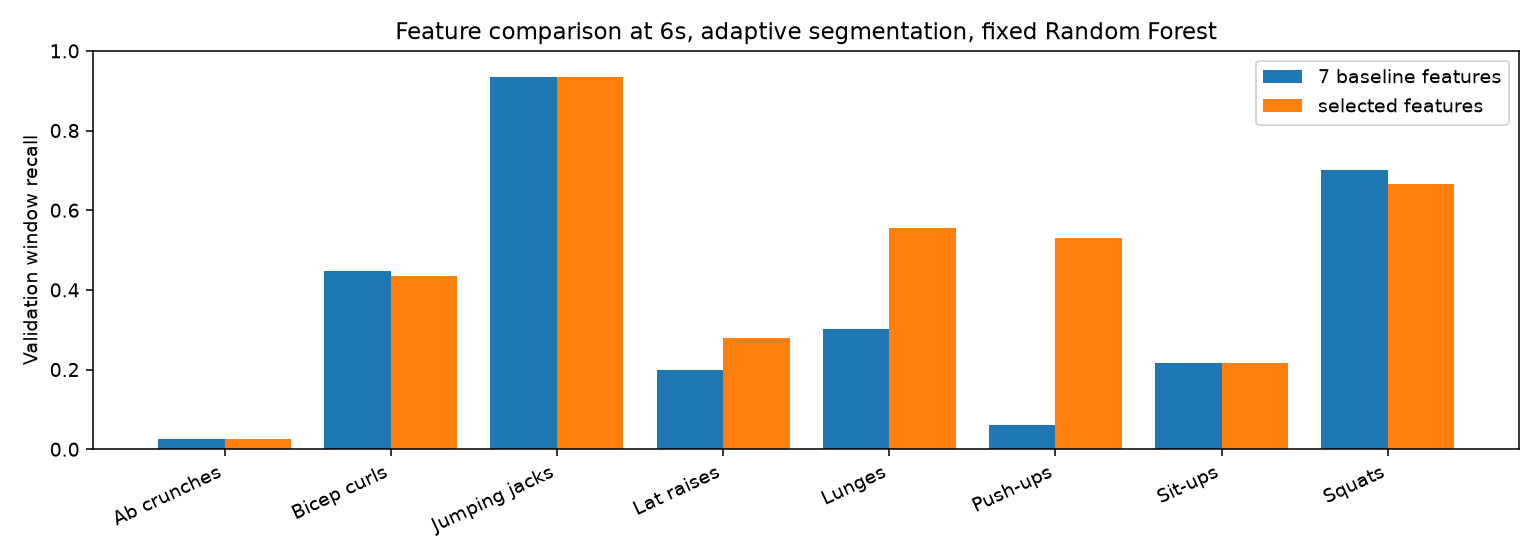

In [12]:
# Step 4: fixed Random Forest; choose window/features using fit + validation only.
feature_results = run_feature_exploration()

print("Baseline-feature window-length comparison:")
display(pd.DataFrame(feature_results['window_comparison'])[
    ['window_sec', 'fit_windows', 'validation_windows', 'validation_window_accuracy']
].round(4))
print("Feature-set comparison at the chosen length:")
display(pd.DataFrame(feature_results['feature_comparison'])[
    ['run', 'feature_count', 'validation_window_accuracy']
].round(4))
print("Segmentation comparison with the selected length/features:")
display(pd.DataFrame(feature_results['segmentation_comparison'])[
    ['segmentation', 'fit_windows', 'validation_windows', 'validation_window_accuracy']
].round(4))
display(Image(filename=feature_results['figure']))

# Use this one setup in the model-comparison sections below.
WINDOW_SEC = feature_results['selected_window_sec']
FEATURES = feature_results['selected_features']
frames = pd.read_csv(feature_results['selected_frames_path'])
train_frames = select_recordings(frames, train_manifest)
fit_frames = select_recordings(frames, fit_manifest)
val_frames = select_recordings(frames, val_manifest)
assert FEATURES == feature_columns(frames)
assert set(frames['recording']).isdisjoint(test_manifest['path'])
print('Locked development setup:', WINDOW_SEC, 'seconds, adaptive segmentation,', len(FEATURES), 'features')
print(FEATURES)
# Build test_frames only after model settings are fixed, for final evaluation.


**For the validation recordings, using a fixed Random Forest:**

| Segmentation | Window length | Features | Window accuracy (validation) |
|---|---|---|---:|
| Adaptive | 2 s | 7 baseline | 47.62% |
| Adaptive | 4 s | 7 baseline | 48.93% |
| Adaptive | 6 s | 7 baseline | 50.09% |
| Adaptive | 6 s | 7 baseline + 9 selected additions | 56.26% |
| None | 6 s | 7 baseline + 9 selected additions | 53.43% |

#### Interpretation of the results

Six seconds scored highest in the declared length comparison, but the gain over
four seconds is only 1.16 percentage points on a small validation set. Longer
windows can include more of a slow rep and resolve frequency more finely; these
results do not establish a universally best length.

The selected additions are axis standard deviations (x/y/z), axis dominance,
strongest-axis dominant frequency, spectral concentration, x–y and y–z
correlations, and RMS acceleration. We tested and dropped x–z correlation in the
selected set. All ten additions scored 54.45%; the selected nine scored 56.26%.
Group and leave-one-out comparisons are in the displayed table and saved results.
Some added features help together even when they do not help on their own.

Adaptive segmentation scored 56.26%, versus 53.43% for no segmentation, 53.35%
for baseline segmentation, and 54.91% for protocol trimming with the same feature
set and window length. These evaluate the same recordings but different windows.
Adaptive also worked well with the counter in Step 3, so keep it as the shared
working method. The final settings for model comparison are **6-second windows,
16 features, and adaptive segmentation**. Test recordings remain reserved.

See `WORK_LOG.md` for per-exercise changes and interpretation limits. These are
window scores on one validation split, not final recording-level results.


## Assignment-Classification1: Decision Tree

In this section, you tune a decision tree and test it on the test recordings. The steps are as follows:

1. **Grid Search**: Do grid search for tuning the hyperparameters (`max_depth` and `criterion` in `train_decision_tree`). Train on the **fit** windows and pick the hyperparameters with the highest accuracy on the **validation** windows. Do not pick hyperparameters by looking at the test accuracy: it is your test set.

2. **Test**: Retrain the decision tree with the best hyperparameters on all the **training** windows (fit + validation), and evaluate it on the **test** windows. Do the same for the default hyperparameters.

3. **Performance Visualization**: Display the confusion matrix of the test windows with matplotlib's `ConfusionMatrixDisplay`. Each row corresponds to a true exercise, and each column to a predicted exercise. With 8 exercises, use a large figure and rotate the labels (`xticks_rotation='vertical'`).

4. **Decision Tree Visualization**: Visualize the decision tree using the `viz_tree` function (loaded from util.py). Pass `list(model.classes_)` as the class names, so the names match the model's order of the classes.

5. **Fill up** this table.

6. **Interpretation of the results**: Which exercises are easy to recognize, and which are confused with each other? Why? What did you learn from hyperparameter tuning?

Reusing the previously frozen validation choices.
Reusing the completed test evaluation; no settings are changed.
Decision Tree default and validation-selected settings:


,model,variant,parameters,validation_window_accuracy,test_window_accuracy,test_macro_f1,training_windows,test_windows
0,decision_tree,default,"{'max_depth': 5, 'criterion': 'entropy', 'clas...",0.4374,0.4843,0.2799,2225,925
1,decision_tree,selected,"{'class_weight': None, 'criterion': 'gini', 'm...",0.5009,0.4649,0.4055,2225,925


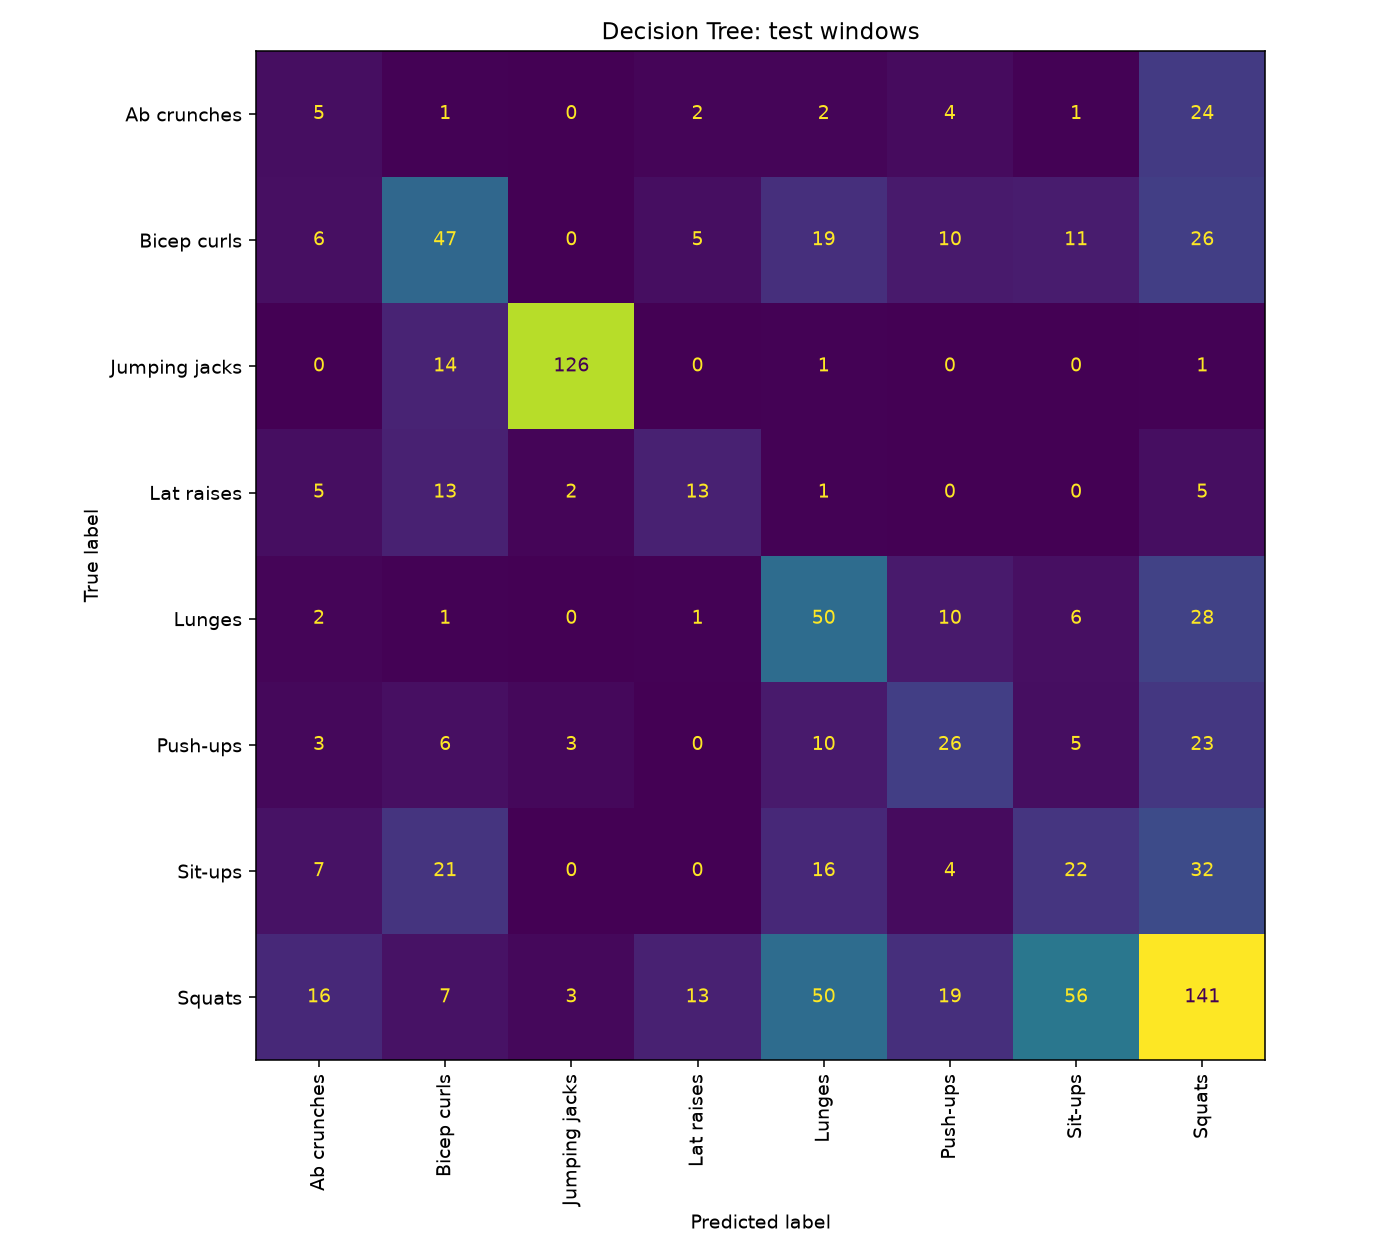

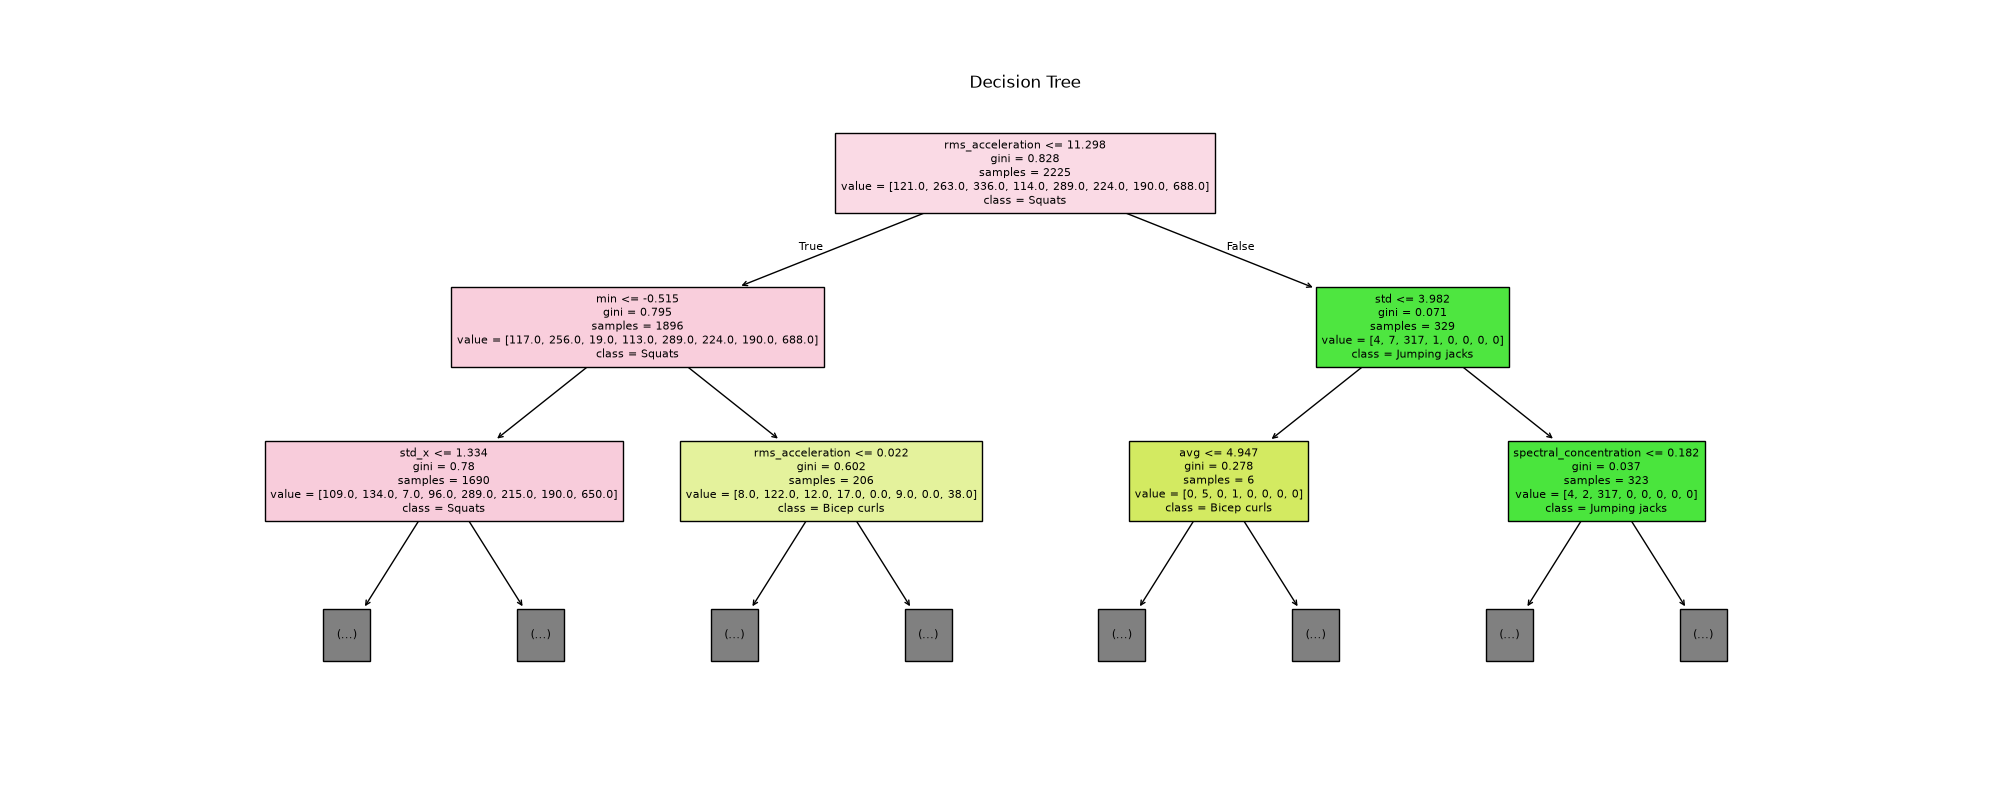

In [13]:
# Tune both families on fit/validation, freeze choices, then evaluate test windows.
# Later runs reuse the frozen artifacts; test scores never select parameters.
classification_results = run_classification_exploration()
model_comparison = pd.DataFrame(classification_results['model_comparison'])
print("Decision Tree default and validation-selected settings:")
display(model_comparison[model_comparison['model'] == 'decision_tree'].round(4))
best_dt_model = joblib.load(classification_results['model_paths']['decision_tree_selected'])
default_dt_model = joblib.load(classification_results['model_paths']['decision_tree_default'])
test_frames = pd.read_csv(classification_results['test_frames_path'])
display(Image(filename=classification_results['figures']['decision_tree_confusion']))

# Required supplied tree visualization. Show only the top two levels for clarity.
original_dir = os.getcwd()
try:
    os.chdir('results/step5_classification/figures')
    viz_tree(best_dt_model, train_frames[FEATURES], list(best_dt_model.classes_), max_depth=2)
    plt.close('all')
finally:
    os.chdir(original_dir)
display(Image(filename=classification_results['figures']['decision_tree_structure']))


**Same six-second windows, 16 features, and adaptive segmentation:**

| Hyperparameters | Window accuracy (validation) | Window accuracy (test) |
|---|---:|---:|
| Default: depth=5, entropy, no weighting | 43.74% | 48.43% |
| Selected: depth=12, Gini, no weighting | 50.09% | 46.49% |

#### Interpretation of the results

The grid searched depth, criterion, and class weighting using fit/validation
recordings only. The selected deeper tree improves validation accuracy but
performs worse on test accuracy than the default. We keep the validation choice
and report that result rather than choosing again from test. Its test macro F1
is 0.406 versus 0.280 for default, so its class-wise tradeoff differs from the
accuracy change. Jumping jacks are comparatively easy; many squats, sit-ups,
lunges, and ab crunches are confused. The plot shows test **windows**, not votes
for entire recordings.


## Assignment-Classification2: A New Classifier

Repeat section Assignment-Classification1 with a different classifier, using the same window length and feature set. It could be Random Forest, kNN, Logistic regression, or any other classifier of your choice (add its import to the imports block). Tune its key hyperparameters the same way (fit → validation), then retrain on all the training windows and evaluate on the test windows. Finally, compare it with the decision tree (model exploration, exploration report §2): did the better model help all exercises equally, or did the gain concentrate on specific exercises?

Notes:
- kNN, Logistic Regression, and SVM are sensitive to feature scale, so standardize the features first (e.g., `make_pipeline(StandardScaler(), KNeighborsClassifier())`).
- The classes are imbalanced (106 squats vs 19 lat raises). Many models have `class_weight='balanced'`. Try it and see what happens to the small classes.

Random Forest default and validation-selected settings:
Selected models: test-window recall by exercise:
Model family selected before test access: random_forest


,model,variant,parameters,validation_window_accuracy,test_window_accuracy,test_macro_f1,training_windows,test_windows
2,random_forest,default,"{'n_estimators': 100, 'max_depth': None, 'min_...",0.5626,0.5957,0.4926,2225,925
3,random_forest,selected,"{'class_weight': 'balanced', 'max_depth': None...",0.5662,0.6043,0.5532,2225,925


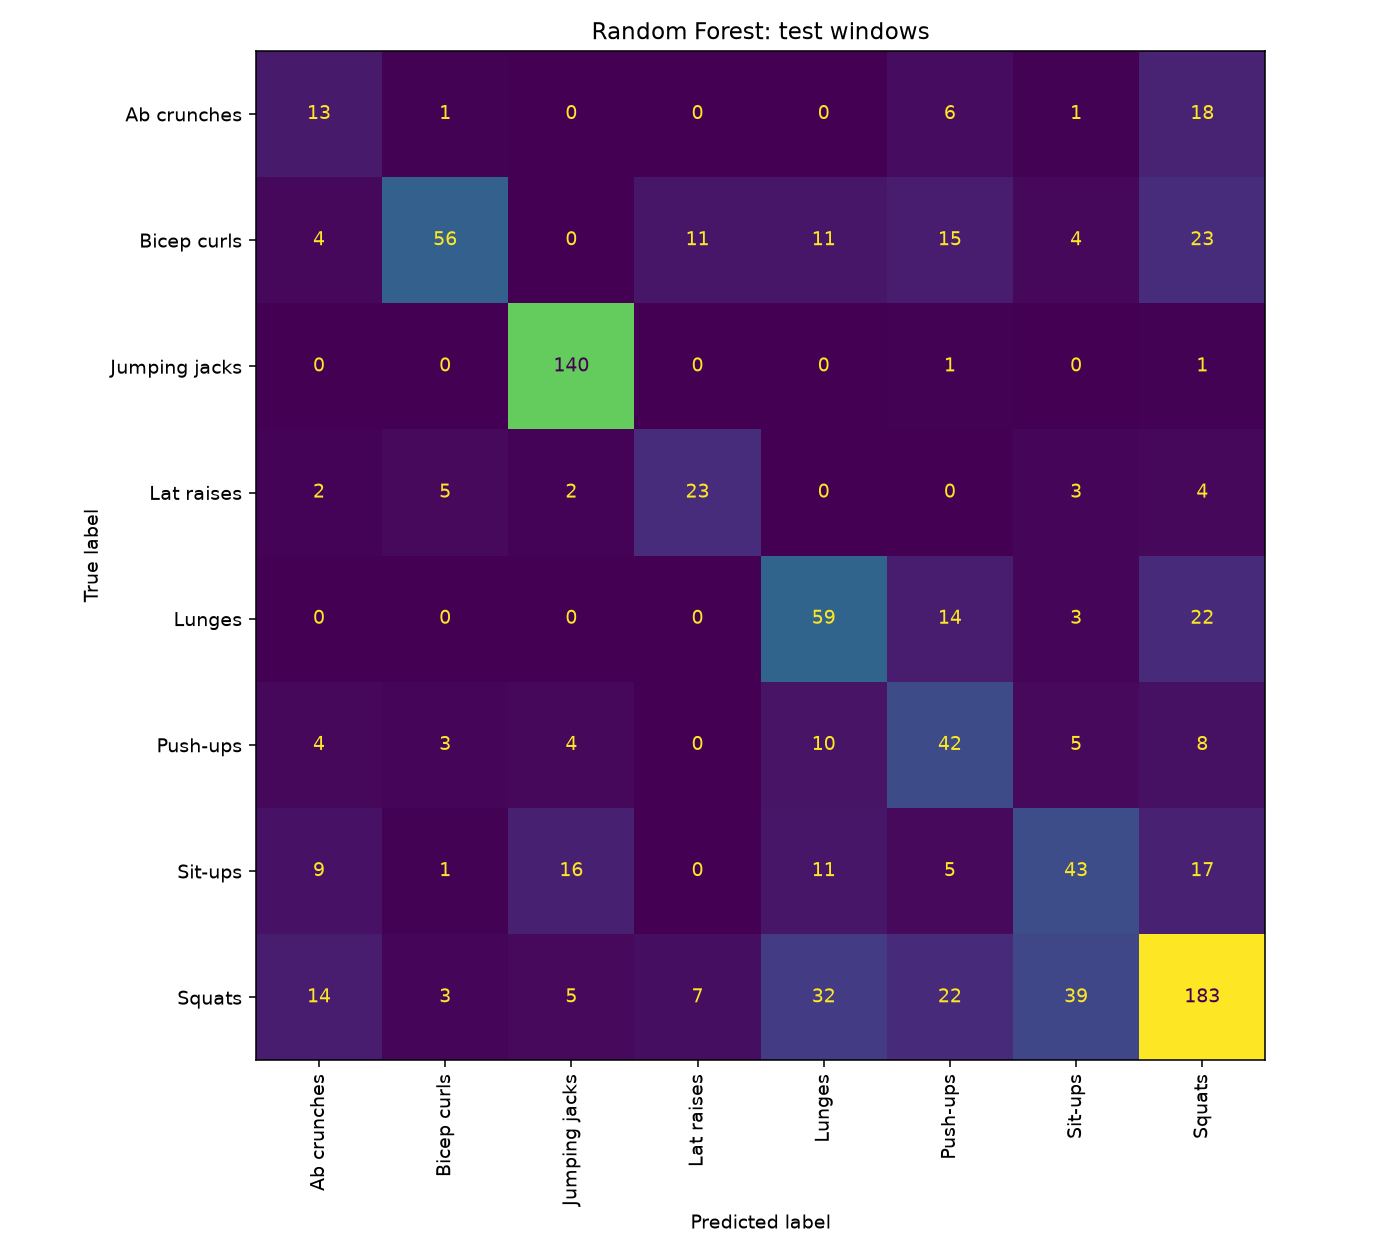

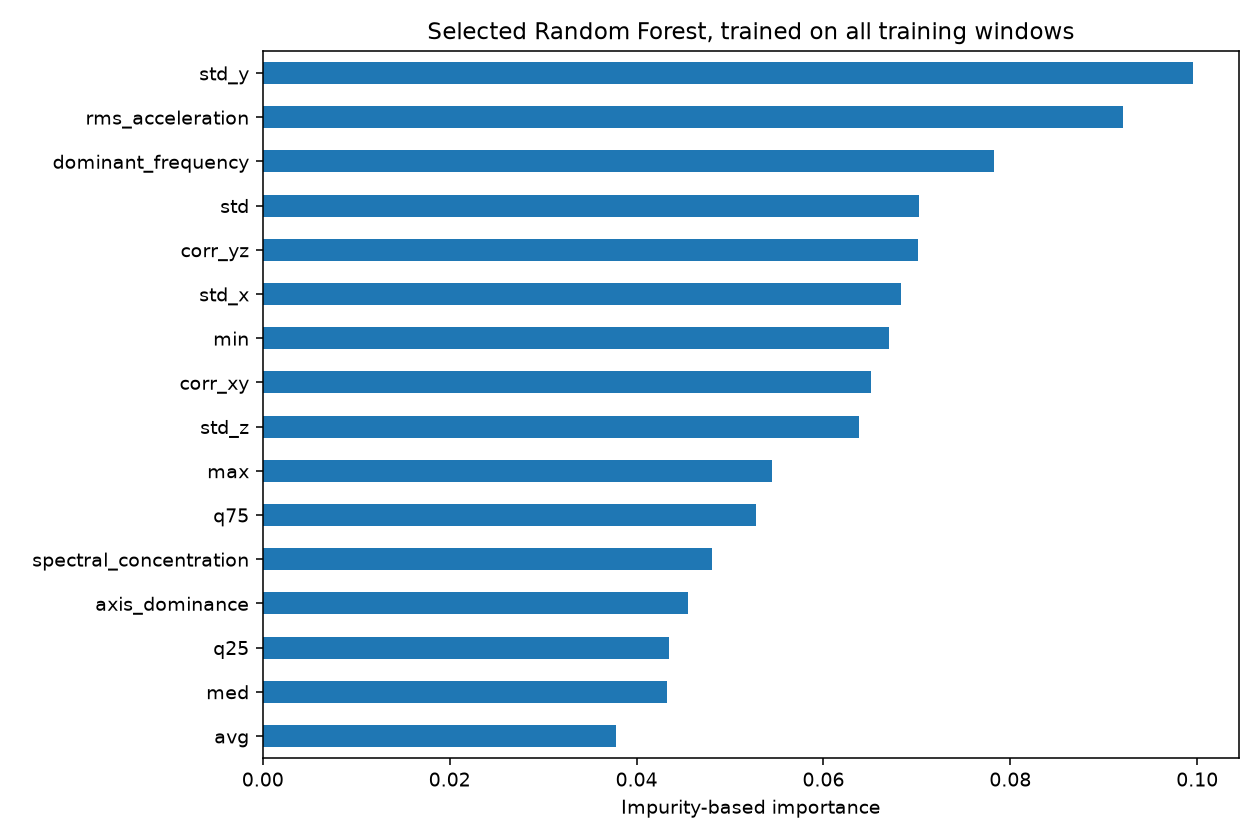

model,decision_tree,random_forest
exercise,,
Ab crunches,0.1282,0.3333
Bicep curls,0.3790,0.4516
Jumping jacks,0.8873,0.9859
Lat raises,0.3333,0.5897
Lunges,0.5102,0.6020
Push-ups,0.3421,0.5526
Sit-ups,0.2157,0.4216
Squats,0.4623,0.6000


In [14]:
# Both classifiers use the same fixed feature/window/segmentation setup.
print("Random Forest default and validation-selected settings:")
display(model_comparison[model_comparison['model'] == 'random_forest'].round(4))
best_rf_model = joblib.load(classification_results['model_paths']['random_forest_selected'])
default_rf_model = joblib.load(classification_results['model_paths']['random_forest_default'])
display(Image(filename=classification_results['figures']['random_forest_confusion']))
display(Image(filename=classification_results['figures']['forest_feature_importances']))

print("Selected models: test-window recall by exercise:")
model_class_results = pd.read_csv('results/step5_classification/selected_models_test_by_exercise.csv')
display(model_class_results.pivot(index='exercise', columns='model', values='recall').round(4))
print('Model family selected before test access:', classification_results['selected_model_family'])


**Same six-second windows, 16 features, and adaptive segmentation:**

| Model | Hyperparameters | Window accuracy (validation) | Window accuracy (test) |
|---|---|---:|---:|
| Default Random Forest | 100 trees, no weighting | 56.26% | 59.57% |
| Selected Random Forest | 200 trees, unlimited depth, minimum leaf=1, balanced weights | 56.62% | 60.43% |

#### Interpretation and comparison to the Decision Tree

The selected forest has higher test-window accuracy than the selected tree
(60.43% versus 46.49%) and improves recall for every exercise, with unequal gains.
The larger recall gains include lat raises, push-ups, sit-ups, and ab crunches;
bicep curls improve less. Ab crunches remain difficult despite improvement.

The forest's tuning gain is small: only two more validation windows are correct
than for the default forest. At matched 200-tree settings, class balancing adds
one correct validation window overall while increasing several smaller-class
recalls and reducing squat recall. It does not help every class. Test macro F1
is 0.553 for the selected forest versus 0.406 for the selected tree.

The forest family and its settings were selected by validation before loading
test signals. We retain those frozen choices. The feature-importance plot is
impurity-based; correlated inputs can share importance, so do not interpret it
as proof of a physical cause. Recording-level voting is the next step.


###  Assignment: Function 4: predict_recordings(model, frames, features)

So far every accuracy is a **window** accuracy. A real app gives one answer per recording, so aggregate the window predictions of each recording into one label (exploration report §4).

**Hints and Instructions:**
- The function takes as arguments:
  - `model`: a trained classifier
  - `frames`: a feature DataFrame with the `exercise` and `recording` columns
  - `features`: the feature columns the model was trained on
- The function will perform the following:
  - Predict the label of every window
  - Group the predictions by `recording` and take the most common label (majority vote). You may also try confidence-weighting with `model.predict_proba`.
  - Return a DataFrame with one row per recording and the columns `recording`, `true`, and `predicted`

In [15]:
def predict_recordings(model, frames, features=None):
    # Most common window label; exact ties use alphabetical order.
    # Returns exactly recording, true, and predicted. No model retraining.
    return vote_recordings(model, frames, features)


## Assignment-Recording-Level Predictions

A real app gives one answer per recording. In this section, you combine the window predictions of each **test** recording into one exercise label.

1. **Recording-level accuracy**: Use `predict_recordings` with your best decision tree and your best new classifier (both trained on all the training windows) on the test windows. Recording-level accuracy = `(recordings['true'] == recordings['predicted']).mean()`.

2. **Confusion matrix**: Display the recording-level confusion matrix of your final pipeline. You will use it in §4 of your exploration report.

3. **Fill up** this table.

4. **Interpretation of the results**: Does the majority vote help? For which exercises? When can it make things worse?

        model  test_recordings  test_windows  window_accuracy  mean_recording_window_accuracy  recording_accuracy  correct_recordings  recording_macro_f1  tied_recordings
decision_tree              129           925         0.464865                        0.475263            0.488372                  63            0.401965               15
random_forest              129           925         0.604324                        0.590383            0.635659                  82            0.590886               11
Final pipeline recording accuracy: 0.6356589147286822
decision_tree test recordings
random_forest test recordings


,model,test_recordings,test_windows,window_accuracy,mean_recording_window_accuracy,recording_accuracy,correct_recordings,recording_macro_f1,tied_recordings
0,decision_tree,129,925,0.4649,0.4753,0.4884,63,0.4020,15
1,random_forest,129,925,0.6043,0.5904,0.6357,82,0.5909,11


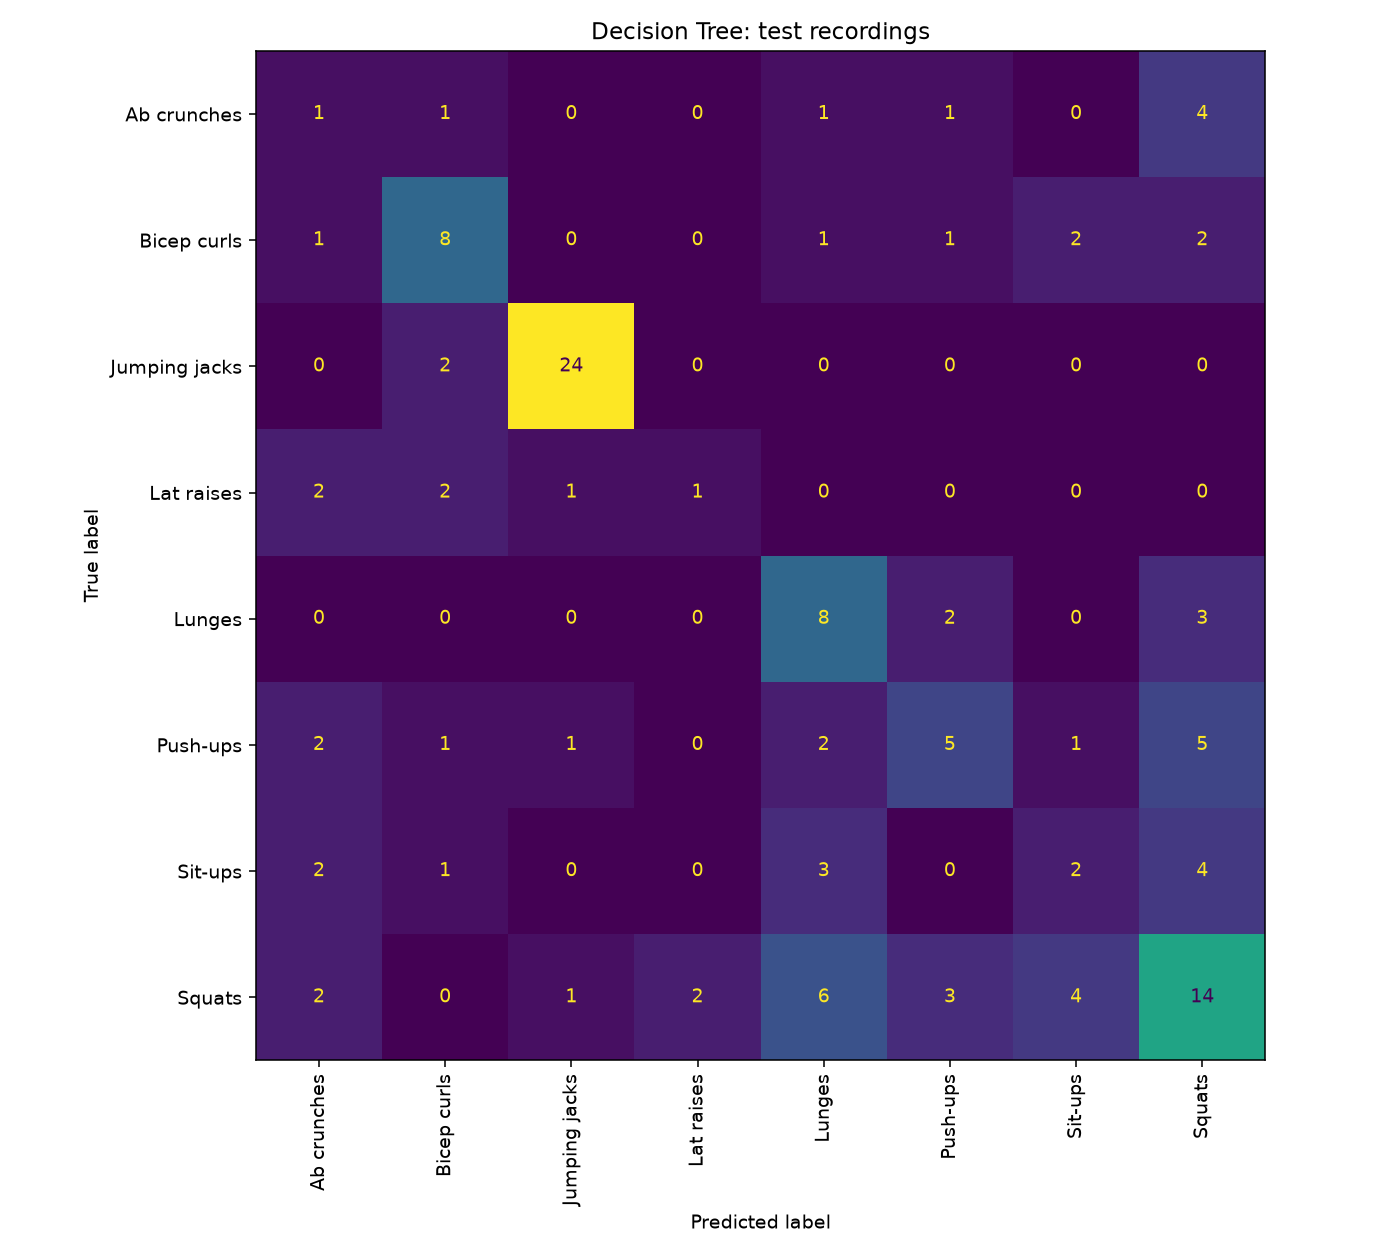

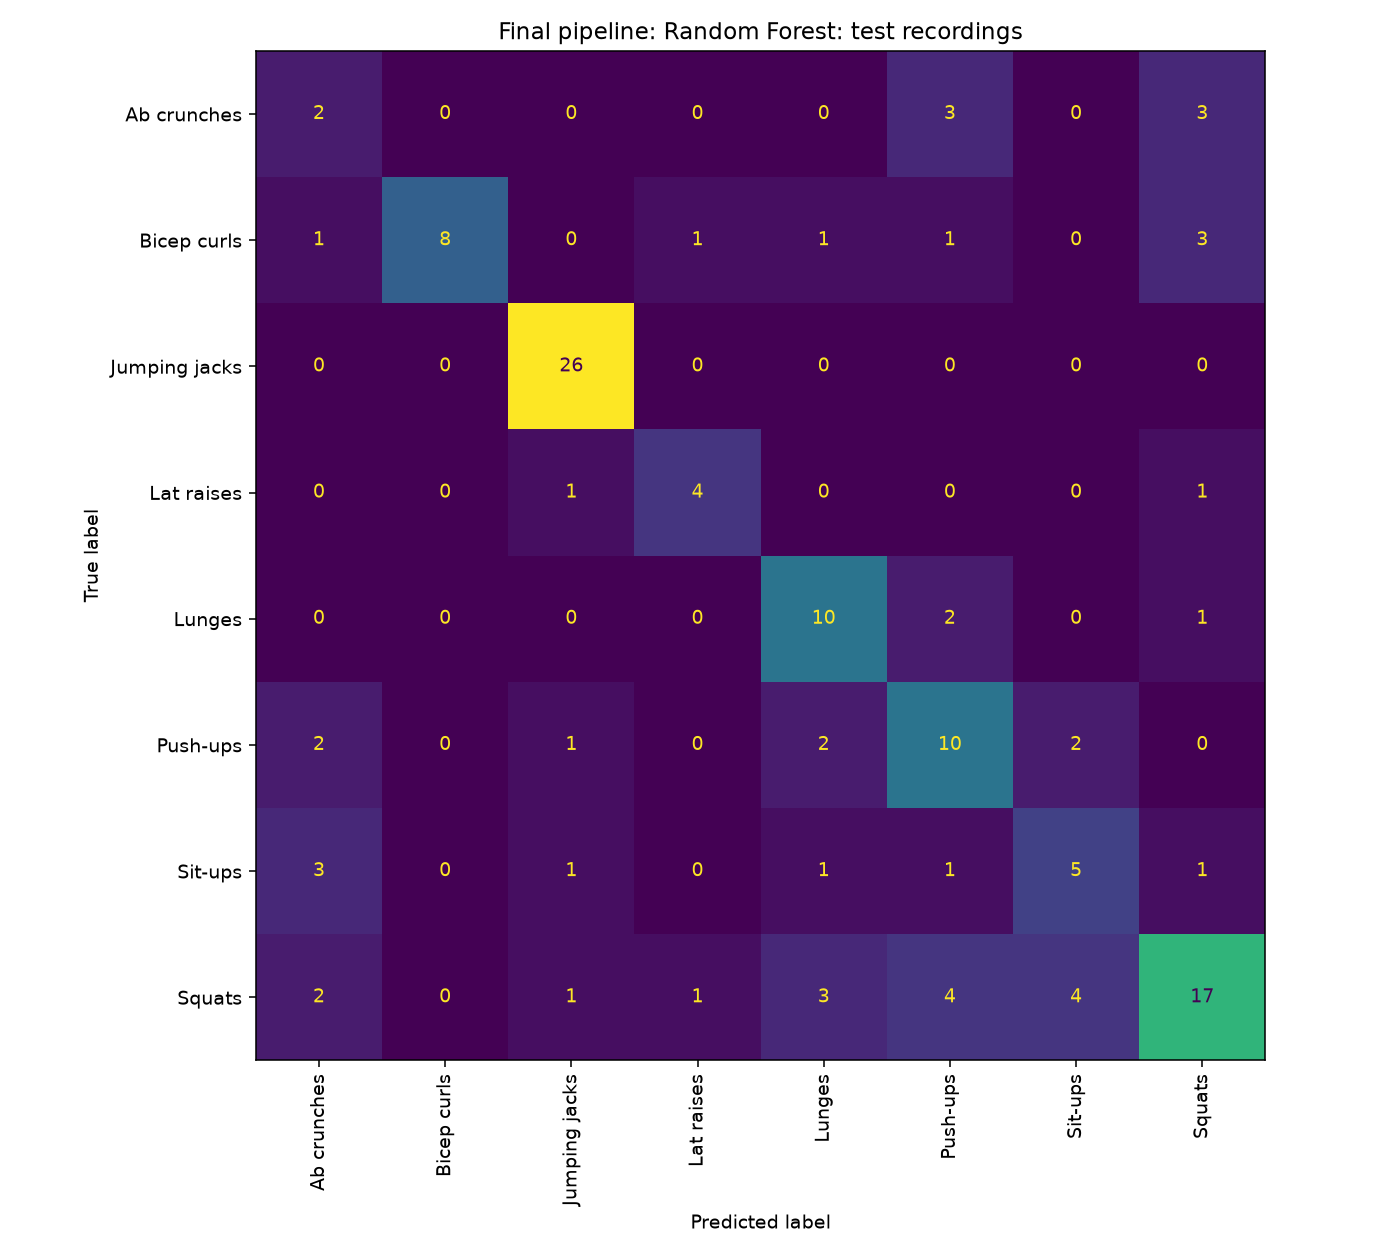

In [16]:
recording_results = run_recording_exploration()
recording_comparison = pd.DataFrame(recording_results['comparison'])
display(recording_comparison.round(4))

dt_recordings = predict_recordings(best_dt_model, test_frames, FEATURES)
rf_recordings = predict_recordings(best_rf_model, test_frames, FEATURES)
# Model family was selected by validation in Step 5, not by these test results.
recordings = {'decision_tree': dt_recordings, 'random_forest': rf_recordings}[
    recording_results['selected_model_family']
]
assert len(recordings) == len(test_manifest) == 129
assert recordings['recording'].is_unique
pd.testing.assert_frame_equal(
    recordings.reset_index(drop=True),
    pd.read_csv('results/step6_recordings/final_recording_predictions.csv')
)
print('Final pipeline recording accuracy:', (recordings['true'] == recordings['predicted']).mean())
for model_name, figure in recording_results['figures'].items():
    print(model_name, 'test recordings')
    display(Image(filename=figure))


**For the test recordings, using the validation-selected models:**

| Model | Window accuracy | Recording accuracy |
|---|---:|---:|
| Decision Tree | 46.49% | 48.84% (63/129) |
| Random Forest | 60.43% | 63.57% (82/129) |

#### Interpretation of the results

Voting helps overall here. It combines noisy window predictions into one answer,
but cannot fix a recording whose windows consistently resemble the wrong class.
The final model remains the Random Forest chosen on validation in Step 5.

Window accuracy gives longer recordings more weight. With equal weight per
recording, mean window accuracy is 47.53% for the tree and 59.04% for the forest;
recording votes score 48.84% and 63.57%. So the observed gain is not only a
change in how recording lengths are weighted.

For the forest, recording recall is 100% for jumping jacks, 76.92% for lunges,
and 66.67% for lat raises, but only 25% for ab crunches. Compared with mean
within-recording window accuracy, voting helps most exercise groups here;
sit-ups and squats decline slightly. Some true-class windows can be outvoted.

There are 11 tied forest votes and 15 tied tree votes. The rule always chooses
the alphabetically first tied label; it was fixed before viewing these results.
For example, sit-ups `024_2026-10-18_23-55-25.csv` has one correct sit-up window
and one ab-crunch prediction. The fixed tie rule returns ab crunches. This
illustrates a limitation, not a reason to change the rule using test outcomes.

The displayed **8 × 8 recording-level** forest matrix is the final pipeline
figure for report §4. Its rows/columns count recordings, not windows. Test error
attribution and trace inspection are Step 7; no settings were changed here.


## Assignment-Failure Analysis (for exploration report §4 and §5)

Pick your final pipeline (exploration report §4) and look at where it fails.

1. **Classification errors**: From the recording-level confusion matrix, find the largest off-diagonal cells (e.g., lat raises predicted as squats). For each one, decide whether it is a **segmentation** problem (the segment is wrong), a **feature** problem (the features do not separate the two exercises), or a **model** problem (the features separate them, but the model fails, e.g., because the class is small).

2. **Rep counting errors**: Find the test recordings with the largest rep errors. Is it the segmentation (phone handling counted as reps, reps cut off), the counting (two peaks per rep, small reps missed), or the label (a wrong reported count)?

3. **Placement**: Merge with `test_manifest` to get the `placement` of each recording. Are the failures concentrated in one placement?

4. **Figures**: For your **top 2 failure modes**, plot one recording with your segment (`plot_segment`). For a rep-counting failure, also plot the signal you count on with the detected peaks. For a classification failure, compare its feature values to the typical (median) feature values of the correct and of the predicted exercise.

Use these figures in §5 of your exploration report.

In [17]:
# Hints, step by step:
# Wrong recordings: recordings[recordings['true'] != recordings['predicted']]
# Placement: test_manifest.merge(recordings, left_on='path', right_on='recording')
# rep_results = evaluate_rep_counter(test_manifest, find_exercise_segment, count_reps)
# Largest rep errors: rep_results.sort_values('error', key=abs, ascending=False).head(10)
# Plot: data, sample_rate = prepare_recording(path); plot_segment(data, {'yours': find_exercise_segment(data, sample_rate)})
# To plot your detected reps, copy the inside of count_reps into a cell and plot the signal with the peaks
# Compare: train_frames.groupby('exercise')[FEATURES].median() vs the feature values of the failing recording

########################### TODO ##########################

#### 🛑 Top 2 failure modes

**Write Below:**